# Analisis de spotify

## Librerias

In [ ]:
#1
"""Librerías para carga, análisis, preprocesamiento y clasificación."""

# Utilidades y carga de archivos
import math
import hashlib
import io
import os
import requests

# Manipulación de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Transformadores y preparación de datos
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# División de datos y búsqueda de hiperparámetros
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold
)

# Modelos de clasificación
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluación de modelos
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    cohen_kappa_score
)
# LIBRERÍAS PARA EXPORTAR MODELOS

import json
import shutil
import joblib

from pathlib import Path
from sklearn.utils.validation import check_is_fitted

## Cargar set de datos

In [ ]:
# obtener hash
#2
url = "https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv"
respuesta = requests.get(url)
hash_calculado = hashlib.sha256(respuesta.content).hexdigest()
print("Hash calculado:", hash_calculado)

Hash calculado: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd


In [ ]:
"""
#3
Script para la descarga y validación criptográfica de un set de datos.

Este bloque de código obtiene un archivo CSV directamente desde un
repositorio de GitHub en su formato Raw. Antes de cargarlo en un
DataFrame de Pandas, utiliza la librería hashlib para generar un
hash SHA-256 del contenido descargado y lo compara con un hash de
referencia (previamente auditado).

El objetivo es garantizar la integridad completa del archivo,
asegurando que los datos no hayan sido alterados, corrompidos ni
manipulados externamente, previniendo así la ejecución de modelos
sesgados o vulnerados.
"""

# 1. Configuración de la URL
url = "https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv"

# 2. Define tu Hash esperado (Copia aquí el hash calculado la primera vez que lo ejecutes)
hash_esperado = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"

# 3. Obtener el contenido del archivo desde la web
respuesta = requests.get(url)
contenido_crudo = respuesta.content # Obtenemos los bytes para el hash

# 4. Generar el Hash Criptográfico (SHA-256) del archivo
hash_calculado = hashlib.sha256(contenido_crudo).hexdigest()

# 5. Validación de Seguridad
if hash_calculado == hash_esperado:
    print("Integridad verificada: El archivo es autentico y no ha sido modificado.")
    # Si es seguro, lo leemos directamente en Pandas
    df = pd.read_csv(io.StringIO(respuesta.text))
    display(df.head())
else:
    print("ALERTA DE SEGURIDAD: El contenido del archivo ha cambiado.")
    print(f"Hash que esperabamos: {hash_esperado}")
    print(f"Hash real obtenido: {hash_calculado}")

Integridad verificada: El archivo es autentico y no ha sido modificado.


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Analisis del set de datos

In [ ]:
#4
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

* **0. Unnamed: 0:** Un índice numérico secuencial que se genera como artefacto al guardar archivos CSV; no aporta valor analítico y suele recomendarse su eliminación.


* **1. track_id:** El identificador alfanumérico único asignado por la API de Spotify a cada pista musical.


* **2. artists:** El nombre del artista, banda o creador que interpreta la canción.


* **3. album_name:** El título del álbum discográfico al que pertenece la pista.
* **4. track_name:** El título oficial de la canción.


* **5. popularity:** Nuestra propuesta de variable objetivo. Es un índice de 0 a 100 calculado por Spotify que refleja el éxito comercial reciente de la pista.


* **6. duration_ms:** La duración física total de la canción, expresada en milisegundos.


* **7. explicit:** Variable lógica booleana (`True` / `False`) que señala si la pista contiene lenguaje para adultos o contenido explícito.
* **8. danceability:** Un indicador acústico (de 0.0 a 1.0) que mide qué tan adecuada es la pista para bailar basándose en su ritmo, estabilidad y fuerza del compás.


* **9. energy:** Métrica (de 0.0 a 1.0) que cuantifica la intensidad, velocidad y percepción de actividad ruidosa de la canción.


* **10. key:** Número entero que mapea la tonalidad musical general de la pista utilizando la notación Pitch Class (por ejemplo, 0 = Do, 1 = Do#, 2 = Re, etc.).
* **11. loudness:** Nivel de volumen general promedio de la canción a lo largo de la pista, medido matemáticamente en decibeles (dB).


* **12. mode:** Indica la modalidad de la escala musical. Utiliza 1 para escalas mayores y 0 para escalas menores.
* **13. speechiness:** Evalúa la exclusividad del habla en la grabación. Valores altos indican contenido casi puramente hablado (como un podcast), mientras que valores bajos indican pistas musicales.
* **14. acousticness:** Nivel de probabilidad estadística (de 0.0 a 1.0) de que la canción sea puramente acústica en lugar de electrónica.


* **15. instrumentalness:** Mide la probabilidad de que una pista no contenga voces humanas. Cifras cercanas a 1.0 indican una pieza netamente instrumental.
* **16. liveness:** Detecta la presencia de una audiencia en la grabación; permite saber si la canción fue interpretada en vivo o grabada en un estudio cerrado.
* **17. valence:** Métrica (de 0.0 a 1.0) que describe la "positividad musical" transmitida. Valores altos denotan emociones felices o eufóricas, y valores bajos indican tristeza, enojo o melancolía.


* **18. tempo:** La velocidad general estimada de la pista, cuantificada en pulsaciones por minuto (BPM).
* **19. time_signature:** Número entero que estima la métrica musical o firma de tiempo (cuántos pulsos conforman un compás, usualmente de 3 a 7).
* **20. track_genre:** Categoría o género musical específico bajo el cual está clasificada la canción.

artist, album_name, track_name poseen 1 solo valor nulo

In [ ]:
#5
df = df.drop(columns=['Unnamed: 0'])

Eliminamos la columna 'Unnamed: 0' Porque no posee ningun valor analitico y solo causará problemas para la integración de un modelo

In [ ]:
"""
#6
Script para detectar y analizar registros duplicados basados en 'track_id'.
"""

# 1. Contar el total de duplicados considerando la combinación de ambas columnas
duplicados_combinados = df.duplicated(subset=['track_id']).sum()
print(f"Total de registros duplicados por track_id: {duplicados_combinados}")

# 2. Visualizar las filas duplicadas para entender la anomalía
# Al usar keep=False, mostramos todas las ocurrencias repetidas juntas para compararlas
df_duplicados = df[df.duplicated(subset=['track_id'], keep=False)]

print("\nDetalle de los primeros registros duplicados (ordenados para comparación):")
display(df_duplicados.sort_values(by=['track_id']).head(10))

Total de registros duplicados por track_id: 24259

Detalle de los primeros registros duplicados (ordenados para comparación):


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,0,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


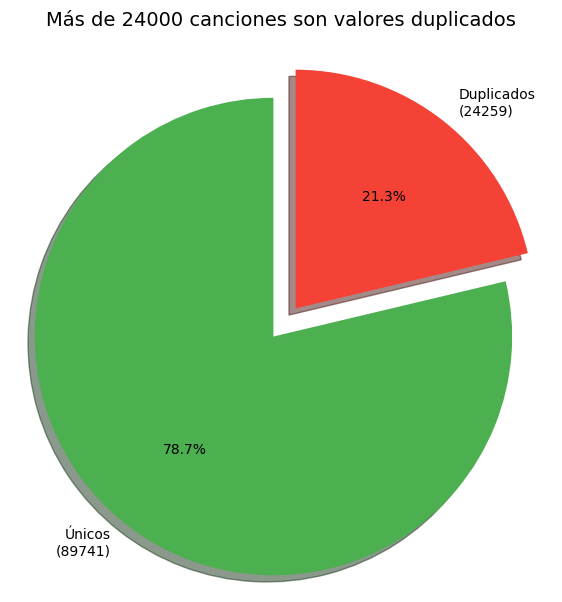

In [ ]:
"""
#7
Script para cuantificar y visualizar registros duplicados.

Este bloque calcula el valor entero exacto de las filas repetidas
basándose en un identificador (track_id). Posteriormente, genera un gráfico de torta que
expone simultáneamente los valores absolutos y sus proporciones
porcentuales para facilitar la auditoría de los datos.
"""

# 1. Calcular los valores enteros exactos
total_duplicados = int(df.duplicated(subset=['track_id']).sum())
total_unicos = int(len(df) - total_duplicados)



# 3. Configurar los parámetros del gráfico
valores = [total_unicos, total_duplicados]
# Integrar el valor entero directamente en la leyenda visual
etiquetas = [f'Únicos\n({total_unicos})', f'Duplicados\n({total_duplicados})']
colores = ['#4CAF50', '#F44336']
desfase = (0, 0.15)

# 4. Construir el gráfico de torta
plt.figure(figsize=(7, 7))
plt.pie(valores,
        labels=etiquetas,
        colors=colores,
        autopct='%1.1f%%',
        explode=desfase,
        startangle=90,
        shadow=True)

# 5. Personalización del lienzo
plt.title("Más de 24000 canciones son valores duplicados", fontsize=14, pad=20)
plt.axis('equal')
plt.show()

### Justificación Técnica: Eliminación de Duplicados por `track_id`

Mantener esta enorme cantidad de registros duplicados (más de 24.000) distorsiona por completo la realidad matemática de nuestro conjunto de datos. Entrenar un algoritmo o modelo estadístico con filas idénticas genera un problema crítico conocido como sobreajuste (*overfitting*).

**¿Por qué fallan los patrones y las métricas se vuelven irreales?**
Al tener una misma canción repetida múltiples veces (conservando sus mismas métricas acústicas de volumen, duración, etc.) solo por una variación en la etiqueta de su género, terminamos engañando al algoritmo. En lugar de aprender el patrón general de comportamiento de los datos, obligamos al modelo a "memorizar" artificialmente estos registros repetidos. Esto hará que el modelo rinda excelente en nuestras pruebas internas, pero fracase por completo al intentar predecir datos nuevos en el mundo real.

**La decisión analítica:**
Para proteger las métricas globales y evitar esta redundancia, la estrategia de ingeniería de datos correcta es ejecutar la eliminación de estas anomalías estructurales, borrando las filas redundantes y preservando únicamente la primera ocurrencia de cada `track_id`.

Asumimos el costo de perder algunas clasificaciones secundarias en la columna del género de la canción, pero a cambio garantizamos un dataset honesto y balanceado. De esta forma, aseguramos que el modelo detecte los verdaderos patrones del éxito musical sin sesgos ni trampas algorítmicas.

In [ ]:
#8
# 1. Eliminar duplicados indicando estrictamente la columna de referencia
df.drop_duplicates(subset=['track_id'], keep='first', inplace=True)

# 2. Resetear el índice del DataFrame para mantener el orden secuencial
df.reset_index(drop=True, inplace=True)

print("Limpieza estructural completada con éxito.")

Limpieza estructural completada con éxito.


In [ ]:
#9
# variables numericas
df_numericas = df.select_dtypes(include=['int64', 'float64'])
df_numericas.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,89741.000000,8.974100e+04,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000
mean,33.198438,2.291418e+05,0.562166,0.634458,5.283549,-8.499004,0.636966,0.087442,0.328289,0.173413,0.216970,0.469477,122.058316,3.897427
std,20.580824,1.129477e+05,0.176691,0.256605,3.559897,5.221490,0.480877,0.113277,0.338321,0.323848,0.194884,0.262864,30.117532,0.453435
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.730400e+05,0.450000,0.457000,2.000000,-10.322000,0.000000,0.036000,0.017100,0.000000,0.098200,0.249000,99.264000,4.000000
50%,33.000000,2.132930e+05,0.576000,0.676000,5.000000,-7.185000,1.000000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,4.000000
75%,49.000000,2.642930e+05,0.692000,0.853000,8.000000,-5.108000,1.000000,0.085900,0.625000,0.097600,0.279000,0.682000,140.077000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


### Análisis Estadístico de las Variables Numéricas

Al leer la tabla generada por `.describe()`, podemos traducir estos números fríos en conclusiones claras sobre la "anatomía" de las canciones en esta muestra de Spotify:

*   **El éxito es difícil de alcanzar (`popularity`):** Aunque el puntaje va del 0 al 100, el promedio (mean) general es bastante bajo, rondando los 33 puntos. Esto significa que el catálogo está lleno de canciones poco conocidas, y los éxitos masivos mundiales son la minoría.

*   **La confirmación de los datos extremos (`duration_ms`):** El promedio de una canción es de aproximadamente 229.000 milisegundos (casi 4 minutos). Sin embargo, el valor máximo (`max`) supera los 5.2 millones (más de 80 minutos). Esto comprueba matemáticamente la existencia de los valores atípicos (*outliers*) extremos que detectamos en los gráficos anteriores.

*   **La regla del 75% (`speechiness` e `instrumentalness`):** Si miramos la fila del 75%, vemos que la gran mayoría de las canciones tienen valores muy bajos en ambas características (menos de 0.1). Esto indica que el catálogo normal es música cantada. Sin embargo, sus valores máximos llegan a casi 1.0, demostrando que existe un pequeño nicho de pistas puramente instrumentales o de voz pura (como podcasts) que alargan la distribución hacia la derecha.

*   **Un catálogo orientado al baile (`danceability` y `energy`):** Los valores promedio y las medianas (el 50%) de ambas variables superan el 0.5. Esto nos confirma que la plataforma está fuertemente poblada por pistas comerciales, dinámicas y enérgicas.

*   **El comportamiento del volumen (`loudness`):** Al medirse matemáticamente en decibeles, sus valores son negativos. La gran mayoría se agrupa entre los -10 y -5 dB (un volumen estándar), pero el registro mínimo (`min`) cae abruptamente hasta los -49.5 dB, justificando la larga cola (sesgo a la izquierda).

Deberiamos llevar duration_ms a minutos

In [ ]:
#10
# variables categoricas
df_categorias = df.select_dtypes(include=['object'])
df_categorias.describe()

,track_id,artists,album_name,track_name,track_genre
count,89741,89740,89740,89740,89741
unique,89741,31437,46589,73608,113
top,2hETkH7cOfqmz3LqZDHZf5,George Jones,The Complete Hank Williams,Rockin' Around The Christmas Tree,acoustic
freq,1,260,110,48,1000


### Análisis Descriptivo de las Variables Categóricas (Texto)

Al evaluar la tabla generada por `.describe()` para nuestras variables de texto, descubrimos los siguientes patrones y alertas sobre la "identidad" de las canciones:

*   **Éxito en la limpieza (`track_id`):** Vemos que hay 89.741 filas en total (`count`) y exactamente 89.741 valores únicos (`unique`). Esto es una excelente noticia: confirma matemáticamente que nuestra eliminación previa de duplicados fue perfecta y ya no hay canciones repetidas.

*   **Alerta de datos faltantes (`count` disparejo):** Si observamos las columnas `artists`, `album_name` y `track_name`, su conteo es de 89.740 (exactamente uno menos que el total). Esto confirma la existencia de **1 fila con valores nulos** (sin nombre ni artista) que ya habíamos detectado en la inspección inicial y que deberemos borrar antes de entrenar el modelo.

*   **Un catálogo muy diverso (`artists`):** Existen 31.437 artistas únicos en esta muestra. El artista con mayor presencia (`top`) es la leyenda del country *George Jones*, aportando 260 canciones (`freq`) a nuestro dataset limpio.

*   **El fenómeno de los nombres repetidos (`track_name`):** Aunque tenemos casi 90 mil canciones únicas, solo hay 73.608 títulos distintos. Esto significa que muchos artistas usan los mismos nombres para sus canciones o hacen *covers*. El caso más extremo es *"Rockin' Around The Christmas Tree"*, un título que aparece 48 veces cantado por distintos intérpretes o en distintas versiones.

*   **La escena musical (`track_genre`):** El catálogo está dividido en 113 géneros musicales únicos. Tras nuestra limpieza de duplicados, el género que logró retener la mayor cantidad de canciones (`top`) es el *acoustic*, con 1.000 pistas.

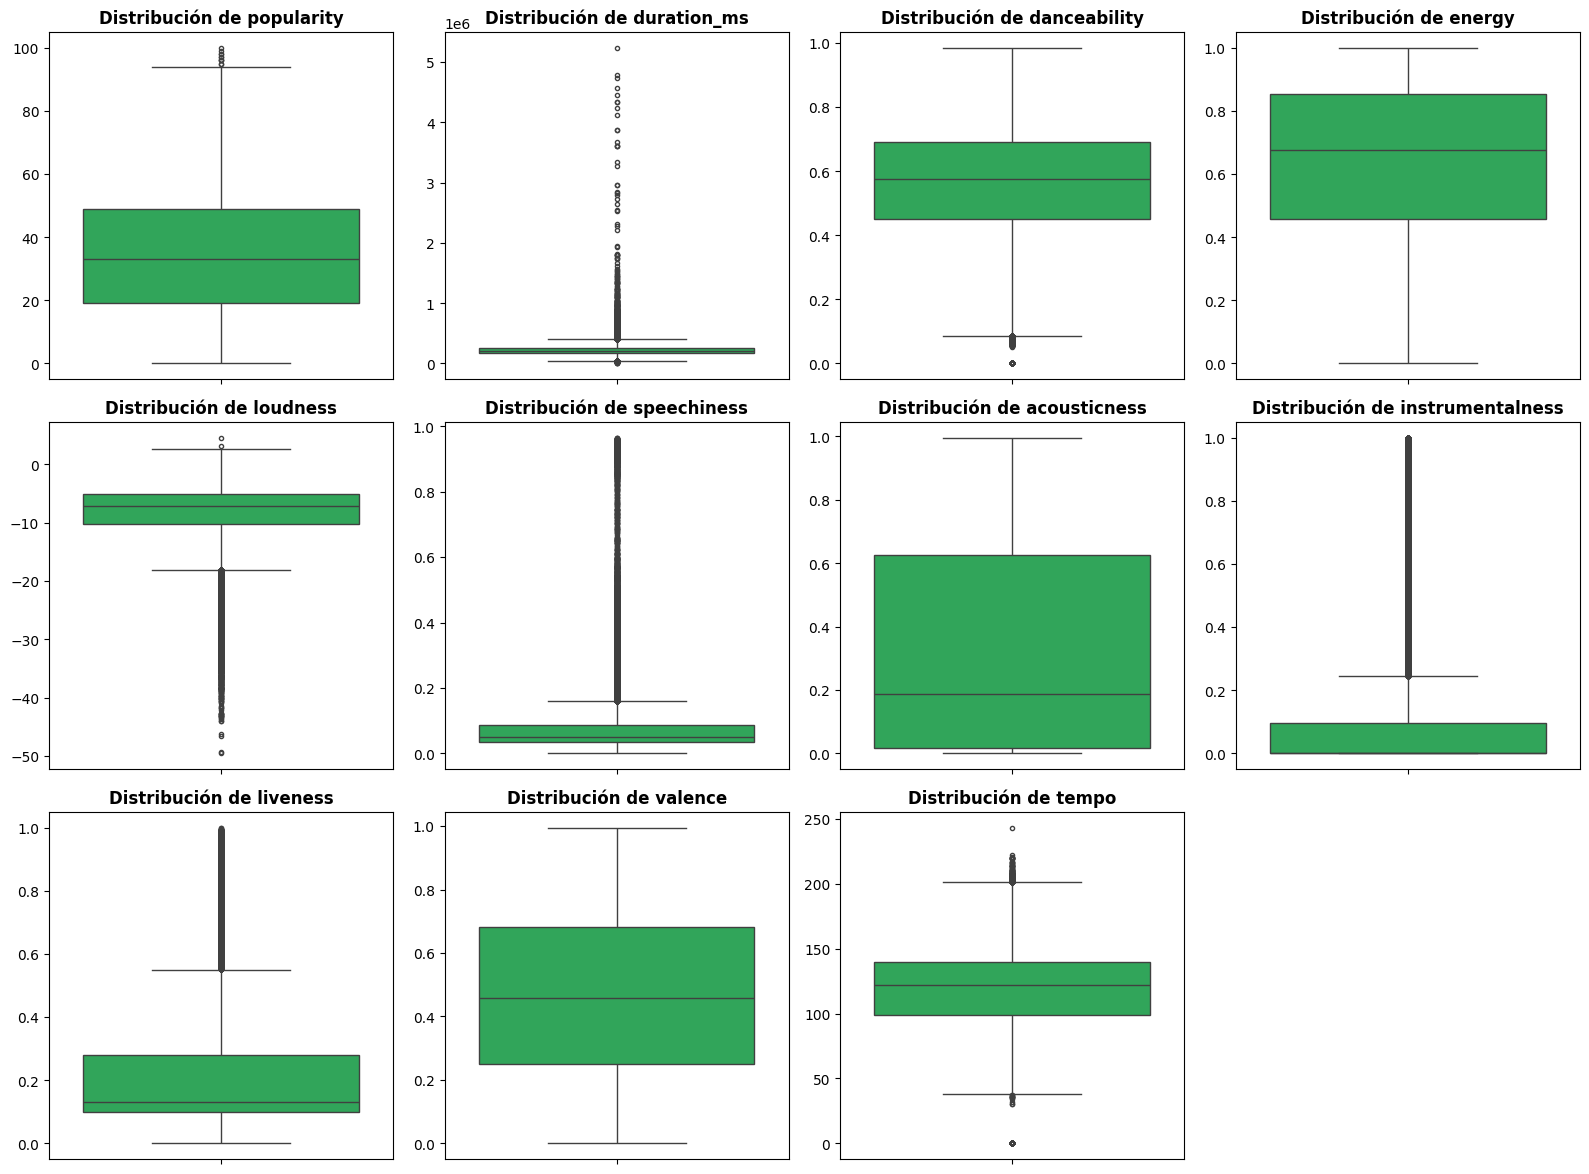

In [ ]:
#11
# 1. Seleccionar numéricas (se recomienda ignorar 'Unnamed: 0' por ser un índice)
df_numericas = df.select_dtypes(include=['int64', 'float64']).drop(columns=['Unnamed: 0', 'mode', 'time_signature', 'key'], errors='ignore')

# 2. Calcular dinámicamente el tamaño de la cuadrícula
columnas = df_numericas.columns
num_cols = len(columnas)
filas = math.ceil(num_cols / 4) # Máximo 4 gráficos por fila

# 3. Configurar el lienzo principal
fig, axes = plt.subplots(nrows=filas, ncols=4, figsize=(16, 4 * filas))
axes = axes.flatten() # Aplanar el arreglo para iterar fácilmente

# 4. Generar un boxplot para cada variable
for i, col in enumerate(columnas):
    sns.boxplot(y=df_numericas[col], ax=axes[i], color='#1DB954', fliersize=3)
    axes[i].set_title(f'Distribución de {col}', fontweight='bold')
    axes[i].set_ylabel('')

# 5. Apagar o limpiar los lienzos sobrantes si la cuadrícula no es exacta
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# Mostrar el resultado final de forma ordenada
plt.tight_layout()
plt.show()

### Conclusiones Visuales: Boxplots vs. Estadística (.describe)

Al contrastar estos diagramas de caja con nuestra tabla estadística previa, confirmamos visualmente la "anatomía" de nuestro catálogo musical:

1.  **La confirmación de los datos extremos (Colas hacia arriba):**
    Variables como `duration_ms`, `speechiness`, `instrumentalness` y `liveness` muestran una "caja" muy aplastada en la parte inferior y una larguísima línea de puntos negros que se dispara hacia arriba. Esto ilustra exactamente lo que vimos en el `.describe()`: la enorme mayoría de las canciones tienen valores bajísimos, pero existen casos raros (como pistas de 80 minutos o podcasts de pura voz) que generan esos atípicos severos (*outliers*).

2.  **El caso inverso del volumen (`loudness`):**
    Al revés que las variables anteriores, la caja del volumen está concentrada en la parte superior (cerca del 0 dB), pero suelta una estela de puntos hacia abajo. Esto demuestra visualmente por qué nuestro valor mínimo (`min`) caía hasta los -49.5 dB: existen pistas inusualmente silenciosas que arrastran la distribución hacia la izquierda.

3.  **Las variables "Saludables" (Distribución simétrica):**
    Métricas como `popularity`, `danceability`, `valence` y `tempo` presentan cajas bien proporcionadas. La línea que las atraviesa (que equivale exactamente al 50% o Mediana de nuestra tabla estadística) está bastante centrada. Esto significa que tienen un comportamiento equilibrado y estable, ideal para que los algoritmos aprendan patrones sin confundirse.



### Análisis de Distribución y Sesgo (Deducido desde Boxplots)

A partir de los diagramas de caja, podemos inferir la forma de la campana de Gauss (distribución normal) para cada variable y diagnosticar su sesgo. El sesgo indica hacia dónde se alarga la "cola" de los datos, lo cual es crítico porque las anomalías extremas pueden destruir la estabilidad de algoritmos basados en regresiones lineales.

*   **Sesgo a la Derecha (Asimetría Positiva):**
    *   **Variables:** `duration_ms`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`.
    *   **Forma en la campana:** El pico (la gran mayoría de los datos) se concentra a la izquierda en los valores muy bajos, y se genera una larga cola arrastrada hacia la derecha.
    *   **Significado:** La mayoría de las canciones en Spotify tienen valores mínimos en estas métricas (ej. son muy poco instrumentales o habladas), pero existen unas pocas excepciones extremadamente altas que generan ruido como valores atípicos (*outliers*).

*   **Sesgo a la Izquierda (Asimetría Negativa):**
    *   **Variables:** `loudness` (muy marcado), `danceability` (leve), `energy` (leve).
    *   **Forma en la campana:** El pico de los datos está acumulado a la derecha (valores altos), con una cola alargada hacia la izquierda.
    *   **Significado:** Casi todo el catálogo comercial tiene un volumen (`loudness`) alto y está masterizado con mucha energía. Las excepciones son pistas inusualmente silenciosas o acústicas, representadas por los *outliers* inferiores.

*   **Distribución Simétrica (Campana Equilibrada):**
    *   **Variables:** `popularity`, `valence`, `tempo`, `key`.
    *   **Forma en la campana:** Se asemejan más a una campana de Gauss tradicional. La línea de la mediana está centrada y los "bigotes" del gráfico son proporcionales en ambos lados.
    *   **Significado:** Los datos se distribuyen equitativamente alrededor de su valor medio, siendo ideales para modelos predictivos sin necesidad de transformaciones drásticas.



#DecisionTreeClassifier: Binario

El árbol binario sirve como experimento para evaluar qué ocurre al simplificar la popularidad en dos grupos, pero esa división pierde información útil para el negocio ya que el resultado es muy ambiguo.

 Una canción con 34 puntos queda en la misma categoría que una con 100, aunque sus niveles de popularidad sean muy distintos.


También una aclaración: el corte es en 33 puntos de popularidad, no en 33 % de las canciones. Ese valor corresponde a la mediana observada del dataset

##Paso 1. Crear las dos categorías de popularidad

In [ ]:
# ============================================================
# PASO 1: CREACIÓN DE LA VARIABLE OBJETIVO BINARIA
# ============================================================
# Se utiliza la mediana observada de popularidad (33)
# para obtener dos clases prácticamente equilibradas.
#
# 0 = Baja popularidad  (popularity <= 33)
# 1 = Alta popularidad  (popularity >= 34)
#
# Se conserva la variable popularity original.

df_bin = df.copy()

df_bin['popularidad_binaria'] = (
    df_bin['popularity'] > 33
).astype(int)

# Verificar distribución de clases
distribucion_bin = pd.DataFrame({
    'Cantidad': df_bin['popularidad_binaria']
        .value_counts().sort_index(),
    'Porcentaje': df_bin['popularidad_binaria']
        .value_counts(normalize=True)
        .sort_index() * 100
})

distribucion_bin.index = [
    'Baja popularidad',
    'Alta popularidad'
]

display(distribucion_bin.round(2))

,Cantidad,Porcentaje
Baja popularidad,45160,50.32
Alta popularidad,44581,49.68


Se eligió 33 como punto de corte porque es la mediana de popularidad del conjunto de datos. La mediana deja aproximadamente la mitad de las observaciones a cada lado, lo que permite obtener dos grupos con tamaños muy similares


Este equilibrio facilita la evaluación: el modelo no puede conseguir una accuracy elevada simplemente eligiendo siempre una clase mucho más numerosa. No se necesita aumentar ni reducir artificialmente la cantidad de canciones de cada grupo y asi evitando el desbalance de esta clase.

**“Alta popularidad” significa aquí estar por encima de la mediana de esta muestra; no significa necesariamente ser un éxito comercial.**

##Paso 2. Seleccionar las variables predictoras y dividir los datos

In [ ]:
# ============================================================
# PASO 2: VARIABLES PREDICTORAS Y DIVISIÓN TRAIN/TEST
# ============================================================
# Se mantienen las mismas características del experimento
# original, sin incorporar el valor numérico de popularidad.
#
# División estratificada 80/20 para preservar el equilibrio
# de ambas clases en entrenamiento y prueba.


# Columnas excluidas del modelado
columnas_descartar_bin = [
    'Unnamed: 0',
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'energy',
    'popularity',
    'popularidad_binaria'
]

# Variables predictoras
X_bin = df_bin.drop(
    columns=columnas_descartar_bin,
    errors='ignore'
)

# Variable objetivo
y_bin = df_bin['popularidad_binaria']

# División estratificada
X_train_bin, X_test_bin, y_train_bin, y_test_bin = (
    train_test_split(
        X_bin,
        y_bin,
        test_size=0.20,
        random_state=42,
        stratify=y_bin
    )
)

print("Dimensiones del conjunto de entrenamiento:")
print(X_train_bin.shape)

print("\nDimensiones del conjunto de prueba:")
print(X_test_bin.shape)

print("\nDistribución porcentual en entrenamiento:")
print(y_train_bin.value_counts(normalize=True).sort_index() * 100)

print("\nDistribución porcentual en prueba:")
print(y_test_bin.value_counts(normalize=True).sort_index() * 100)

Dimensiones del conjunto de entrenamiento:
(71792, 14)

Dimensiones del conjunto de prueba:
(17949, 14)

Distribución porcentual en entrenamiento:
popularidad_binaria
0    50.323156
1    49.676844
Name: proportion, dtype: float64

Distribución porcentual en prueba:
popularidad_binaria
0    50.320352
1    49.679648
Name: proportion, dtype: float64


Se separaron las características utilizadas para predecir de la categoría que se desea identificar. Se excluyeron popularity y popularidad_binaria de los predictores porque contienen directamente la respuesta: incluirlas permitiría al modelo conocer aquello que debería aprender a predecir.


También se excluyeron el índice, el identificador y los nombres de canciones, artistas y álbumes, manteniendo el enfoque en características musicales y género. Se conservó la exclusión previa de energy para seguir la selección de variables del trabajo; eliminarla por correlación no es un requisito de los árboles.


**Los datos se dividieron en 80 % para entrenamiento y 20 % para prueba**

- La división estratificada conserva aproximadamente las proporciones de ambas categorías en los dos conjuntos. random_state=42 permite repetir la misma división y reproducir los resultados.

##Paso 3. Construir el pipeline con outliers

In [ ]:
# ============================================================
# PASO 3: PREPROCESAMIENTO CON OUTLIERS
# ============================================================
# Variables numéricas: passthrough, sin escalamiento.
# Variables categóricas: OneHotEncoder.
#
# No se aplica IQR, winsorización ni eliminación de outliers.
# Los valores extremos válidos se conservan porque pueden
# contener información relevante para la clasificación.

# Variables cualitativas
categorical_features_bin = [
    'explicit',
    'key',
    'mode',
    'time_signature',
    'track_genre'
]

# Variables numéricas
numerical_features_bin = [
    'duration_ms',
    'danceability',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

# Preprocesamiento exclusivo de este experimento
preprocessor_bin = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numerical_features_bin
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features_bin
        )
    ],
    remainder='drop'
)

print("Preprocesador binario definido correctamente.")

Preprocesador binario definido correctamente.


Las variables numéricas se mantuvieron con sus valores originales, sin escalamiento ni recorte de extremos.

Los árboles deciden mediante preguntas como “¿el tempo supera cierto valor?”, por lo que no necesitan que todas las variables tengan una escala semejante.


Se conservaron los valores extremos válidos porque pueden representar canciones particulares que también interesa clasificar. Esto no significa que los árboles sean totalmente inmunes a ellos, sino que no requieren eliminarlos automáticamente.


Las variables categóricas se transformaron con OneHotEncoder, porque el árbol de Scikit-learn necesita entradas numéricas. **handle_unknown='ignore'** evita que una categoría nueva durante la predicción provoque un error.


El preprocesador binario es independiente del resto del trabajo. Además, al incorporarlo al pipeline, las categorías se aprenden utilizando únicamente el conjunto de entrenamiento.

##Paso 4. Crear y entrenar el árbol de decisión

In [ ]:
# ============================================================
# PASO 4: ÁRBOL DE DECISIÓN BINARIO
# ============================================================
# Se entrena un único DecisionTreeClassifier sin búsqueda
# ni ajuste de hiperparámetros.
#
# Se utiliza el pipeline con outliers para mantener la misma
# metodología de preprocesamiento del trabajo original.

# Construir pipeline
dt_bin = Pipeline(
    steps=[
        ('preprocessor', preprocessor_bin),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Entrenamiento
dt_bin.fit(X_train_bin, y_train_bin)

# Predicciones sobre el conjunto de prueba
y_pred_bin = dt_bin.predict(X_test_bin)

# Predicciones de entrenamiento para analizar generalización
y_pred_train_bin = dt_bin.predict(X_train_bin)

print("Árbol de decisión binario entrenado correctamente.")

Árbol de decisión binario entrenado correctamente.


Se entrenó un DecisionTreeClassifier con sus parámetros predeterminados, fijando únicamente **random_state=42**. No se buscaron mejores hiperparámetros porque el objetivo era evaluar un árbol básico en este experimento.


El modelo aprendió con los datos de entrenamiento y después realizó predicciones sobre las canciones de prueba. También se generaron predicciones de entrenamiento para comprobar posteriormente si su rendimiento se mantiene al enfrentarse a datos que no utilizó para aprender

##Paso 5. Calcular las métricas

In [ ]:
# ============================================================
# PASO 5: MÉTRICAS DE CLASIFICACIÓN BINARIA
# ============================================================
# Accuracy, Precision, Recall y F1-score.
#
# Se considera como clase positiva:
# 1 = Alta popularidad.
#
# Esto permite evaluar específicamente qué tan bien
# identifica el modelo las canciones del grupo alto.

accuracy_bin = accuracy_score(
    y_test_bin, y_pred_bin
)

precision_bin = precision_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

recall_bin = recall_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

f1_bin = f1_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

# Tabla de métricas
metricas_bin = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score'
    ],
    'Valor': [
        accuracy_bin,
        precision_bin,
        recall_bin,
        f1_bin
    ]
})

print("=== MÉTRICAS DEL ÁRBOL BINARIO ===")
display(metricas_bin.round(4))

# Reporte adicional por categoría
print("\n=== REPORTE POR CLASE ===")

print(
    classification_report(
        y_test_bin,
        y_pred_bin,
        labels=[0, 1],
        target_names=[
            'Baja popularidad',
            'Alta popularidad'
        ],
        zero_division=0
    )
)

=== MÉTRICAS DEL ÁRBOL BINARIO ===


,Métrica,Valor
0,Accuracy,0.7505
1,Precision,0.7518
2,Recall,0.7431
3,F1-score,0.7474



=== REPORTE POR CLASE ===
                  precision    recall  f1-score   support

Baja popularidad       0.75      0.76      0.75      9032
Alta popularidad       0.75      0.74      0.75      8917

        accuracy                           0.75     17949
       macro avg       0.75      0.75      0.75     17949
    weighted avg       0.75      0.75      0.75     17949



Se consideró alta popularidad como la clase positiva, porque interesa evaluar específicamente la identificación de ese grupo. Aquí precision, recall y F1 se refieren a esa categoría.

- **Accuracy: 75,05 %**	- Clasificó correctamente aproximadamente 75 de cada 100 canciones del conjunto de prueba.
- **Precision	75,18 %**	- De las canciones que señaló como de alta popularidad, aproximadamente 75 de cada 100 realmente pertenecían a ese grupo.
- **Recall	74,31 %** -	Identificó aproximadamente 74 de cada 100 canciones que realmente tenían alta popularidad.
- **F1-score	0,7474**	- Resume el equilibrio entre precision y recall para la categoría alta. No representa un porcentaje de aciertos.

Como las clases están equilibradas, predecir siempre la categoría mayoritaria daría aproximadamente 50,32 % de accuracy. El 75,05 % obtenido supera esa referencia, aunque todavía presenta errores relevantes

##Paso 6. Crear la matriz de confusión

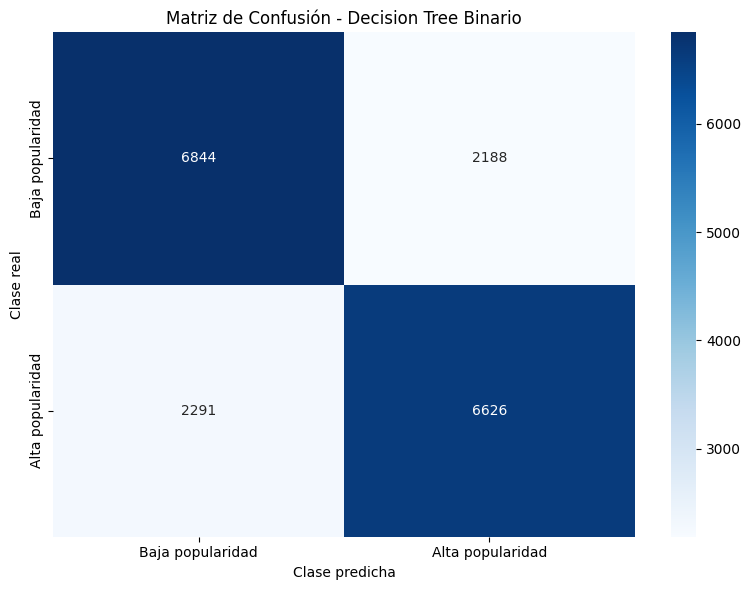

In [ ]:
# ============================================================
# PASO 6: MATRIZ DE CONFUSIÓN BINARIA
# ============================================================
# Permite identificar verdaderos negativos, falsos positivos,
# falsos negativos y verdaderos positivos.
#
# Clase 0 = Baja popularidad
# Clase 1 = Alta popularidad


cm_bin = confusion_matrix(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_bin,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Baja popularidad',
        'Alta popularidad'
    ],
    yticklabels=[
        'Baja popularidad',
        'Alta popularidad'
    ]
)

plt.title('Matriz de Confusión - Decision Tree Binario')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.tight_layout()
plt.show()

##Paso 7. Interpretación automática de la matriz

In [ ]:
# ============================================================
# PASO 7: INTERPRETACIÓN DE LA MATRIZ DE CONFUSIÓN
# ============================================================
# Se extraen los cuatro resultados de la matriz y se
# interpretan según el objetivo comercial.

vn, fp, fn, vp = cm_bin.ravel()

print("=== INTERPRETACIÓN DE RESULTADOS ===")

print(f"\nVerdaderos Negativos (VN): {vn}")
print(
    f"El modelo identificó correctamente {vn} canciones "
    "de baja popularidad."
)

print(f"\nFalsos Positivos (FP): {fp}")
print(
    f"El modelo clasificó {fp} canciones de baja "
    "popularidad como si fueran de alta popularidad."
)

print(f"\nFalsos Negativos (FN): {fn}")
print(
    f"El modelo no consiguió identificar {fn} canciones "
    "que realmente pertenecían al grupo de alta popularidad."
)

print(f"\nVerdaderos Positivos (VP): {vp}")
print(
    f"El modelo identificó correctamente {vp} canciones "
    "de alta popularidad."
)

print("\n=== RESUMEN COMERCIAL ===")
print(f"Accuracy: {accuracy_bin:.2%}")
print(f"Precision: {precision_bin:.2%}")
print(f"Recall: {recall_bin:.2%}")
print(f"F1-score: {f1_bin:.2%}")

=== INTERPRETACIÓN DE RESULTADOS ===

Verdaderos Negativos (VN): 6844
El modelo identificó correctamente 6844 canciones de baja popularidad.

Falsos Positivos (FP): 2188
El modelo clasificó 2188 canciones de baja popularidad como si fueran de alta popularidad.

Falsos Negativos (FN): 2291
El modelo no consiguió identificar 2291 canciones que realmente pertenecían al grupo de alta popularidad.

Verdaderos Positivos (VP): 6626
El modelo identificó correctamente 6626 canciones de alta popularidad.

=== RESUMEN COMERCIAL ===
Accuracy: 75.05%
Precision: 75.18%
Recall: 74.31%
F1-score: 74.74%


- **Verdaderos negativos - 6.844 -**	Canciones realmente de baja popularidad que el modelo clasificó correctamente como bajas.


- **Falsos positivos - 2.188 -** Canciones de baja popularidad clasificadas como altas. Si se seleccionaran para promoción basándose en el modelo, podrían recibir recursos por una expectativa equivocada.


- **Falsos negativos	2.291** -	Canciones de alta popularidad clasificadas como bajas. Podrían quedar fuera de una selección y representar oportunidades desaprovechadas.


- **Verdaderos positivos	6.626**	- Canciones de alta popularidad correctamente identificadas. Son los aciertos directamente relacionados con detectar el grupo de interés.

En total, el modelo acertó **13.470** canciones y se equivocó en **4.479.**

**Para entender especialmente la categoría alta**:
- De las 8.917 canciones realmente altas, detectó 6.626 y dejó pasar 2.291. Esto equivale a detectar el 74,31 % y perder el 25,69 %.
- De las 8.814 canciones que predijo como altas, 6.626 lo eran y 2.188 eran bajas. Por tanto, el 24,82 % de sus selecciones como “alta” fueron incorrectas.

La idea de prestar especial atención a las canciones populares es razonable, pero conviene observar los verdaderos positivos junto con los errores que los acompañan. Su cantidad aislada no basta: un modelo que clasificara todas las canciones como altas detectaría todas las populares, pero también señalaría incorrectamente todas las bajas.

Como el objetivo es encontrar la mayor cantidad posible de canciones populares pondría el foco en el recall de alta popularidad, acompañado siempre de F1.

**Importante:**

 - identificar características asociadas con popularidad no demuestra que copiarlas produzca éxito. Este experimento clasifica la popularidad observada; no demuestra qué causa el éxito ni predice por sí solo la popularidad futura de un lanzamiento

##Paso 8. Comparar entrenamiento y prueba

In [ ]:
# ============================================================
# PASO 8: ANÁLISIS DEL POSIBLE SOBREAJUSTE
# ============================================================
# Se comparan métricas de entrenamiento y prueba.
#
# Una diferencia considerable puede indicar que el árbol
# memorizó patrones específicos de entrenamiento y no
# generaliza adecuadamente.

metricas_train_test_bin = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'F1-score'
    ],
    'Entrenamiento': [
        accuracy_score(
            y_train_bin,
            y_pred_train_bin
        ),
        f1_score(
            y_train_bin,
            y_pred_train_bin
        )
    ],
    'Prueba': [
        accuracy_bin,
        f1_bin
    ]
})

metricas_train_test_bin['Brecha'] = (
    metricas_train_test_bin['Entrenamiento']
    - metricas_train_test_bin['Prueba']
)

display(metricas_train_test_bin.round(4))

,Métrica,Entrenamiento,Prueba,Brecha
0,Accuracy,0.9957,0.7505,0.2453
1,F1-score,0.9957,0.7474,0.2483


Se compararon las métricas para comprobar si el árbol mantiene su desempeño con canciones que no utilizó durante el aprendizaje.

La diferencia es una señal clara de **sobreajuste**: el árbol se adapta muy bien a las canciones de entrenamiento, pero pierde bastante rendimiento con las de prueba.

Es compatible con un árbol que aprende detalles demasiado específicos del conjunto utilizado para entrenarlo.

Por tanto, el experimento muestra que separar dos grupos equilibrados permite obtener un desempeño superior a la referencia mayoritaria, pero el árbol básico presenta sobreajuste y la categoría “alta” sigue siendo demasiado amplia para representar éxito comercial. Un resultado mayor que el del árbol de tres categorías tampoco demuestra que sea un mejor modelo para el negocio: está resolviendo una tarea distinta y mas simple

#Clasificacion con 3 categorias

La clasificación en tres categorías permite distinguir canciones de popularidad baja, media y alta con mayor detalle que el experimento binario. Sin embargo, hay un resultado importante: el árbol optimizado mejora sus métricas generales, pero detecta menos canciones realmente altas que el árbol base.

###Paso 1. Clasificación de popularidad en rangos

Distribución de popularidad por categorías:


,Cantidad,Porcentaje
Baja (0-24),33385,37.20
Media (25-49),35147,39.16
Alta (50-100),21209,23.63


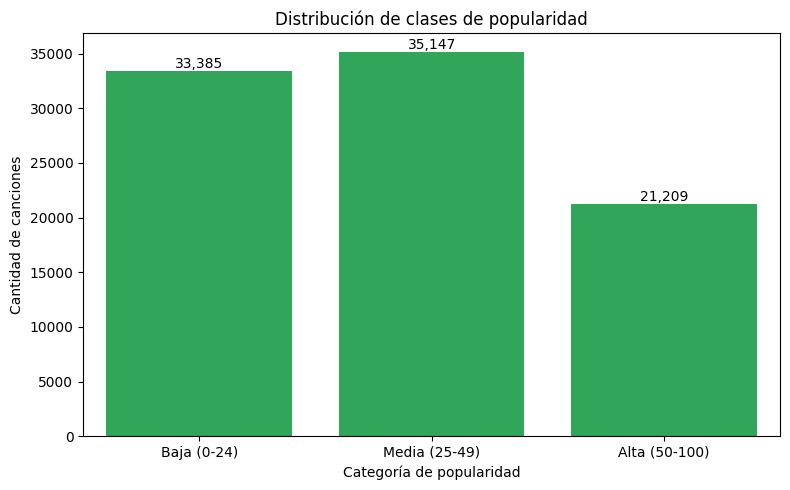

In [ ]:
# PASO 1: Clasificación de popularidad en tres categorías

# Crear nueva variable objetivo sin alterar popularity
df['popularidad_clase'] = pd.cut(
    df['popularity'],
    bins=[-1, 24, 49, 100],
    labels=[0, 1, 2]
).astype(int)

# Nombres descriptivos de las clases
nombres_clases = [
    'Baja (0-24)',
    'Media (25-49)',
    'Alta (50-100)'
]

# Comprobar distribución absoluta y porcentual
distribucion = (
    df['popularidad_clase']
    .value_counts()
    .sort_index()
    .to_frame(name='Cantidad')
)

distribucion['Porcentaje'] = (
    distribucion['Cantidad'] / len(df) * 100
).round(2)

distribucion.index = nombres_clases

print("Distribución de popularidad por categorías:")
display(distribucion)

# Visualizar distribución de clases
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='popularidad_clase',
    order=[0, 1, 2],
    color='#1DB954'
)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(nombres_clases)

plt.title('Distribución de clases de popularidad')
plt.xlabel('Categoría de popularidad')
plt.ylabel('Cantidad de canciones')

for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(
        f'{int(altura):,}',
        (barra.get_x() + barra.get_width() / 2, altura),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

**Se convirtió el puntaje original de popularidad en tres grupos:**

Esta división conserva un nivel intermedio, evitando agrupar canciones de popularidad moderada con aquellas de mayor popularidad. Las categorías tienen un orden: baja < media < alta.


Los cortes son una definición práctica del proyecto, no una garantía de éxito comercial ni unos límites universales de Spotify. Además, asignar códigos 0, 1 y 2 permite representar las clases, pero el árbol multiclase no utiliza automáticamente su orden

**¿Cómo se consideró el desbalance?**

La categoría alta tiene menos canciones, aunque sigue contando con más de 21.000 ejemplos. Se decidió conservar la distribución observada y considerar el desbalance mediante:
- **División estratificada:** mantener las proporciones en entrenamiento y prueba.
-** Validación cruzada estratificada**: conservar aproximadamente esas proporciones en las divisiones utilizadas durante la optimización.
- **F1 macro:** dar la misma importancia a cada categoría al seleccionar el modelo.
- **Reporte por clase:** comprobar específicamente el desempeño en popularidad alta

**No se igualaron las cantidades de canciones**. El código no aplica sobremuestreo, reducción de muestras ni pesos de clase.
**La estratificación conserva el desbalance**; F1 macro evita que la evaluación favorezca únicamente a las clases más numerosas.

**Ninguna de estas dos medidas garantiza por sí sola mejorar la detección de canciones altas.**

###Paso 2. Definición de X e y y selección de variables

In [ ]:
# PASO 2: Definir X e y para clasificación

# Target categórico
y = df['popularidad_clase']

# Variables descartadas según el EDA previo
columns_to_drop = [
    'Unnamed: 0',
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'energy',
    'popularity',
    'popularidad_clase'
]

# Matriz de predictores
X = df.drop(
    columns=columns_to_drop,
    errors='ignore'
)

# Variables categóricas
categorical_features = [
    'explicit',
    'key',
    'mode',
    'time_signature',
    'track_genre'
]

# Variables numéricas
numerical_features = [
    'duration_ms',
    'danceability',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

print("Dimensión de X:", X.shape)
print("Dimensión de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nClases del target:")
print(y.value_counts().sort_index())

Dimensión de X: (89741, 14)
Dimensión de y: (89741,)

Variables predictoras:
['duration_ms', 'explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Clases del target:
popularidad_clase
0    33385
1    35147
2    21209
Name: count, dtype: int64


Se definió popularidad_clase como la respuesta que el modelo debe predecir y se seleccionaron 14 características como predictores.


Se excluyeron popularity y popularidad_clase de los predictores para impedir que el árbol tuviera acceso a la respuesta. También se excluyeron identificadores y nombres, manteniendo el enfoque en características musicales y género.


Se conservó la exclusión previa de energy para mantener la selección de variables del trabajo. Esta decisión debe presentarse como una elección del proyecto: **los árboles no requieren eliminar una variable únicamente porque esté correlacionada con otra.**

###Paso 3. División estratificada Train/Test

In [ ]:
# PASO 3: División de datos estratificada

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

# Comprobar proporciones
print("\nDistribución porcentual en TRAIN:")
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nDistribución porcentual en TEST:")
print(
    y_test.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Registros de entrenamiento: 71792
Registros de prueba: 17949

Distribución porcentual en TRAIN:
popularidad_clase
0    37.20
1    39.16
2    23.63
Name: proportion, dtype: float64

Distribución porcentual en TEST:
popularidad_clase
0    37.20
1    39.17
2    23.63
Name: proportion, dtype: float64


**Se destinó el 80 % al entrenamiento y el 20 % a la prueba:**

La división estratificada permite que ambos conjuntos mantengan aproximadamente un 37 % de canciones bajas, un 39 % medias y un 24 % altas.

Esto evita que la evaluación cambie demasiado por una distribución accidentalmente distinta. **random_state=42** permite reproducir la misma división.

###Paso 4. Pipeline con outliers

In [ ]:
# PASO 4: Preprocesamiento conservando outliers

# Variables categóricas nominales
categorical_features = [
    'key',
    'time_signature',
    'track_genre'
]

# Variables binarias
binary_features = [
    'explicit',
    'mode'
]

# Preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        ),
        (
            'bin',
            'passthrough',
            binary_features
        )
    ],
    remainder='drop'
)

print("Preprocesador configurado correctamente.")
print("Outliers: conservados")
print("Variables numéricas: sin escalamiento")
print("Variables categóricas: OneHotEncoder")

Preprocesador configurado correctamente.
Outliers: conservados
Variables numéricas: sin escalamiento
Variables categóricas: OneHotEncoder


Las variables numéricas se utilizaron sin escalamiento ni recorte de valores extremos. Los árboles realizan divisiones mediante umbrales, por lo que no necesitan poner todas las características en una misma escala.


Se conservaron los extremos válidos porque también pueden representar canciones que interesa clasificar. Los valores extremos no deben confundirse automáticamente con errores de datos

**key, time_signature, track_genre**: *OneHotEncoder*	- Representarlas numéricamente sin imponer un orden artificial.

**explicit, mode**:	*Valores originales* -	Ya tienen dos valores y pueden utilizarse directamente.

El preprocesamiento se incorporó al pipeline para aprender las categorías únicamente con los datos de entrenamiento.

#**DecisionTreeClassifier**

##Paso 5. Entrenamiento y evaluación del modelo base

In [ ]:
# PASO 5: Entrenamiento del árbol base

modelo_base = Pipeline(
    steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Entrenar modelo base
modelo_base.fit(X_train, y_train)

# Predicciones sobre entrenamiento y prueba
y_pred_train_base = modelo_base.predict(X_train)
y_pred_base = modelo_base.predict(X_test)

# Métricas de entrenamiento
f1_train_base = f1_score(
    y_train,
    y_pred_train_base,
    average='macro',
    zero_division=0
)

# Métricas de prueba
accuracy_base = accuracy_score(y_test, y_pred_base)

precision_base = precision_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

recall_base = recall_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

f1_base = f1_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

print("=== DECISION TREE BASE ===")
print(f"Accuracy TEST : {accuracy_base:.4f}")
print(f"Precision TEST: {precision_base:.4f}")
print(f"Recall TEST   : {recall_base:.4f}")
print(f"F1 Macro TEST : {f1_base:.4f}")

print(f"\nF1 Macro TRAIN: {f1_train_base:.4f}")

print("\nReporte por clase:")
print(
    classification_report(
        y_test,
        y_pred_base,
        labels=[0, 1, 2],
        target_names=nombres_clases,
        zero_division=0
    )
)

=== DECISION TREE BASE ===
Accuracy TEST : 0.6244
Precision TEST: 0.6109
Recall TEST   : 0.6102
F1 Macro TEST : 0.6104

F1 Macro TRAIN: 0.9930

Reporte por clase:
               precision    recall  f1-score   support

  Baja (0-24)       0.69      0.72      0.70      6677
Media (25-49)       0.61      0.61      0.61      7030
Alta (50-100)       0.52      0.51      0.51      4242

     accuracy                           0.62     17949
    macro avg       0.61      0.61      0.61     17949
 weighted avg       0.62      0.62      0.62     17949



Se entrenó un árbol con sus parámetros predeterminados, fijando **random_state**=42.

Este modelo constituye la referencia inicial para comprobar si la búsqueda de hiperparámetros aporta una mejora.

La accuracy indica que clasificó correctamente aproximadamente 62 de cada 100 canciones.

Las métricas macro calculan el resultado de cada categoría y después los promedian, dando el mismo peso a baja, media y alta.

Esto es útil ante el desbalance, pero el recall macro de 0,6102 no significa que detecte el 61,02 % de las canciones altas. Para conocer eso debemos revisar el recall específico de alta popularidad

##Paso 6. Optimización mediante GridSearchCV

In [ ]:
# PASO 6: Optimización mediante GridSearchCV

# Crear pipeline del modelo a optimizar
modelo_grid = Pipeline(
    steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Combinaciones de hiperparámetros
param_grid = {
    'classifier__max_depth': [8, 16, None],
    'classifier__min_samples_split': [2, 20],
    'classifier__min_samples_leaf': [1, 10],
    'classifier__criterion': ['gini', 'entropy']
}

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Configuración de GridSearchCV
grid_search = GridSearchCV(
    estimator=modelo_grid,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    error_score='raise',
    return_train_score=True
)

# Buscar hiperparámetros usando SOLO entrenamiento
grid_search.fit(X_train, y_train)

print("\n=== MEJORES HIPERPARÁMETROS ===")
print(grid_search.best_params_)

print("\nMejor F1 Macro en validación cruzada:")
print(f"{grid_search.best_score_:.4f}")

Fitting 4 folds for each of 24 candidates, totalling 96 fits

=== MEJORES HIPERPARÁMETROS ===
{'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Mejor F1 Macro en validación cruzada:
0.6223


**max_depth**	: Cuántos niveles puede alcanzar el árbol.

**min_samples_split**: Cuántas canciones necesita un nodo para poder dividirse.

**min_samples_leaf**:	Cuántas canciones deben quedar como mínimo en un grupo final.

**criterion**:	Cómo se evalúa la calidad de una división.

La búsqueda utilizó cuatro divisiones estratificadas del conjunto de entrenamiento. Así, cada configuración se evaluó varias veces antes de elegirla.

Se seleccionó la configuración con mayor F1 macro, buscando equilibrio entre las tres categorías. La prueba final no participó en esa búsqueda.

El mejor F1 macro de validación cruzada mostrado fue 0,6223. Este valor corresponde a las evaluaciones dentro del entrenamiento, no al conjunto de prueba final.

##Paso 7. Evaluación del modelo optimizado

In [ ]:
# PASO 7: Evaluación del modelo optimizado

# Recuperar el mejor pipeline completo
modelo_optimizado = grid_search.best_estimator_

# Predicciones
y_pred_train_opt = modelo_optimizado.predict(X_train)
y_pred_opt = modelo_optimizado.predict(X_test)

# F1 entrenamiento
f1_train_opt = f1_score(
    y_train,
    y_pred_train_opt,
    average='macro',
    zero_division=0
)

# Métricas en prueba
accuracy_opt = accuracy_score(y_test, y_pred_opt)

precision_opt = precision_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

recall_opt = recall_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

f1_opt = f1_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

print("=== DECISION TREE OPTIMIZADO ===")

print(f"Accuracy TEST : {accuracy_opt:.4f}")
print(f"Precision TEST: {precision_opt:.4f}")
print(f"Recall TEST   : {recall_opt:.4f}")
print(f"F1 Macro TEST : {f1_opt:.4f}")

print(f"\nF1 Macro TRAIN: {f1_train_opt:.4f}")

print("\nReporte por clase:")
print(
    classification_report(
        y_test,
        y_pred_opt,
        labels=[0, 1, 2],
        target_names=nombres_clases,
        zero_division=0
    )
)

=== DECISION TREE OPTIMIZADO ===
Accuracy TEST : 0.6428
Precision TEST: 0.6294
Recall TEST   : 0.6244
F1 Macro TEST : 0.6261

F1 Macro TRAIN: 0.7836

Reporte por clase:
               precision    recall  f1-score   support

  Baja (0-24)       0.71      0.74      0.72      6677
Media (25-49)       0.63      0.64      0.64      7030
Alta (50-100)       0.55      0.49      0.52      4242

     accuracy                           0.64     17949
    macro avg       0.63      0.62      0.63     17949
 weighted avg       0.64      0.64      0.64     17949



Se recuperó el pipeline y se evaluó sobre el mismo conjunto de prueba utilizado con el árbol base.

Mantener el mismo conjunto de prueba y el mismo preprocesamiento permite comparar los dos árboles de forma consistente.
Los resultados muestran una mejora general, pero todavía es necesario comprobar si esa mejora también beneficia a la categoría alta.

##Paso 8. Comparación de métricas

=== COMPARACIÓN DE MODELOS ===


,Métrica,Árbol Base,Árbol Optimizado,Diferencia
0,Accuracy,0.6244,0.6428,0.0184
1,Precision Macro,0.6109,0.6294,0.0184
2,Recall Macro,0.6102,0.6244,0.0142
3,F1 Macro,0.6104,0.6261,0.0156



=== ANÁLISIS DE GENERALIZACIÓN ===


,Modelo,F1 Train,F1 Test,Brecha Train-Test
0,Base,0.9930,0.6104,0.3825
1,Optimizado,0.7836,0.6261,0.1575


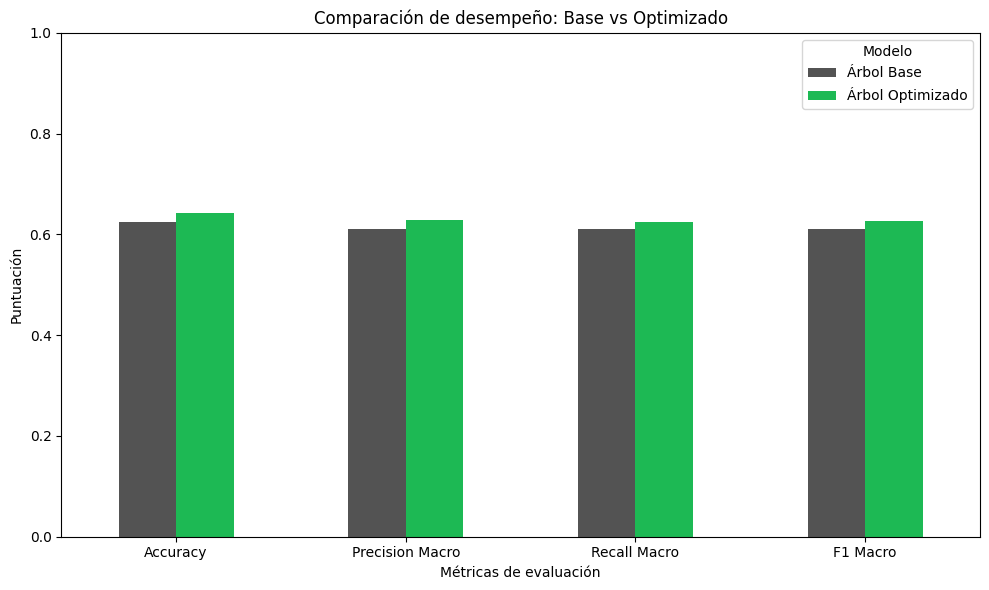

In [ ]:
# PASO 8: Comparación de métricas

comparacion = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro'
    ],
    'Árbol Base': [
        accuracy_base,
        precision_base,
        recall_base,
        f1_base
    ],
    'Árbol Optimizado': [
        accuracy_opt,
        precision_opt,
        recall_opt,
        f1_opt
    ]
})

comparacion['Diferencia'] = (
    comparacion['Árbol Optimizado'] -
    comparacion['Árbol Base']
)

print("=== COMPARACIÓN DE MODELOS ===")
display(comparacion.round(4))

# Comparación de sobreajuste
comparacion_overfitting = pd.DataFrame({
    'Modelo': ['Base', 'Optimizado'],
    'F1 Train': [f1_train_base, f1_train_opt],
    'F1 Test': [f1_base, f1_opt]
})

comparacion_overfitting['Brecha Train-Test'] = (
    comparacion_overfitting['F1 Train'] -
    comparacion_overfitting['F1 Test']
)

print("\n=== ANÁLISIS DE GENERALIZACIÓN ===")
display(comparacion_overfitting.round(4))

# Gráfico de métricas
comparacion_grafico = comparacion.set_index('Métrica')[
    ['Árbol Base', 'Árbol Optimizado']
]

comparacion_grafico.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#535353', '#1DB954']
)

plt.title('Comparación de desempeño: Base vs Optimizado')
plt.xlabel('Métricas de evaluación')
plt.ylabel('Puntuación')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

La optimización aumentó la accuracy aproximadamente 1,84 puntos porcentuales y el F1 macro alrededor de 0,0156.

El árbol base obtiene un resultado casi perfecto sobre las canciones con las que aprendió, pero pierde bastante rendimiento en prueba. Esto indica sobreajuste.

**El optimizado reduce esa diferencia y mejora ligeramente en prueba. El sobreajuste disminuye, aunque sigue existiendo una separación relevante entre ambos resultados.**

##Paso 9. Matrices de confusión e interpretación

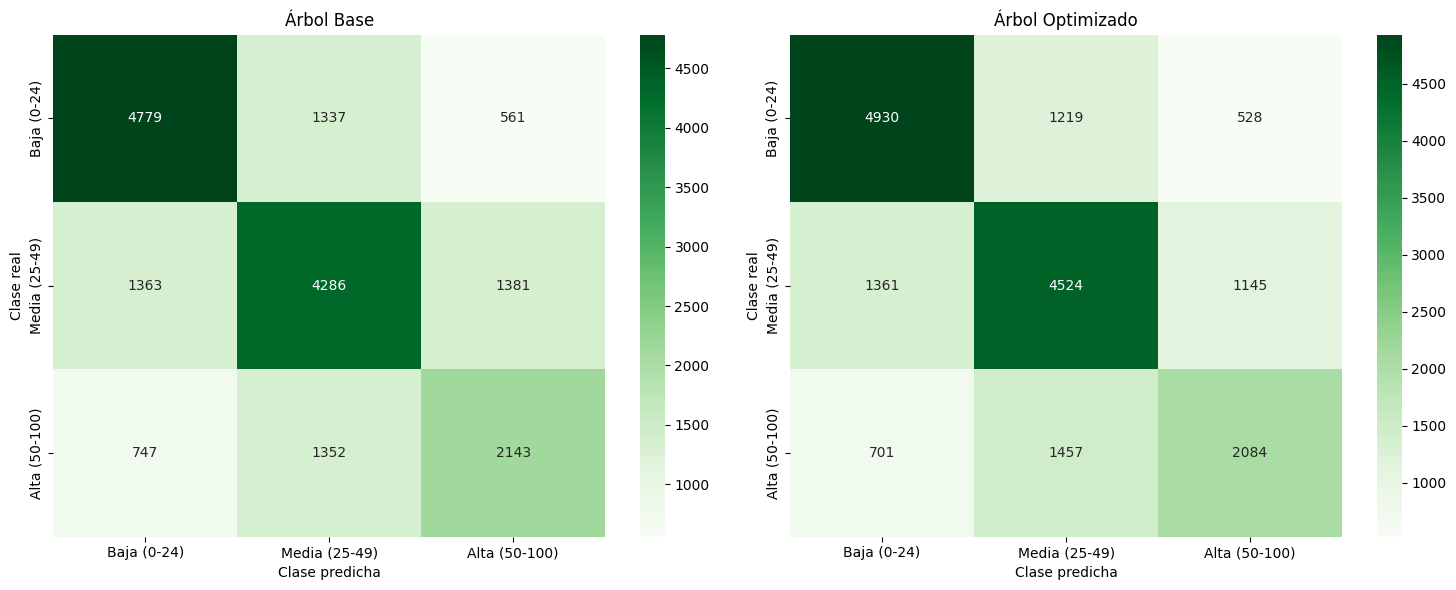

In [ ]:
# PASO 9: Matrices de confusión comparativas

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

modelos = [
    ('Árbol Base', y_pred_base),
    ('Árbol Optimizado', y_pred_opt)
]

for ax, (titulo, predicciones) in zip(axes, modelos):

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1, 2]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.tight_layout()
plt.show()

**En las dos matrices:**
- Las filas indican la categoría real.
- Las columnas indican la categoría predicha.
- La diagonal contiene los aciertos.
- Las demás celdas muestran entre qué categorías se confunde el modelo.

**Por ejemplo, en el árbol optimizado:**
- **1.145, en fila media y columna alta:** canciones realmente medias que fueron clasificadas como altas.
- **1.457, en fila alta y columna media:** canciones realmente altas que fueron clasificadas como medias.
- **2.084, en fila alta y columna alta:** canciones altas identificadas correctamente.

**¿Dónde debemos fijarnos si interesa encontrar las canciones realmente altas?**
- Primero, en la última fila: contiene todas las canciones que realmente son altas y permite saber cuántas detectamos y cuántas dejamos pasar.
Después, en la última columna: contiene todas las canciones seleccionadas como altas y permite saber cuántas selecciones son correctas.

**Recall de alta:** cuántas canciones realmente altas encontramos
- De las 4.242 canciones realmente altas, el optimizado detectó 2.084 y dejó pasar 2.158. Identifica aproximadamente 49 de cada 100 y pierde aproximadamente 51.

**Precision de alta:** cuántas selecciones como altas son correctas
- De las 3.757 canciones que señaló como altas, 2.084 realmente lo eran. Aproximadamente 55 de cada 100 selecciones fueron correctas; las otras 45 pertenecían a baja o media


El optimizado **selecciona altas con mayor precisión**, pero **deja escapar más canciones realmente altas**. Detecta 59 menos y reduce en 269 las selecciones incorrectas como alta.

Para el objetivo de encontrar las canciones que realmente pertenecen al grupo alto, la métrica principal es el recall de alta, porque muestra qué proporción de esas canciones conseguimos recuperar. Debemos acompañarla de precision para comprobar cuántas selecciones incorrectas genera.

**Por tanto:**
- Si importa detectar la mayor cantidad de canciones altas, el árbol base es ligeramente mejor en estos resultados.
- Si importa seleccionar canciones con menos errores para asignar recursos limitados, el optimizado ofrece mayor precision.
- F1 de alta resume ambas prioridades, y favorece ligeramente al optimizado.

Esto explica por qué mejorar F1 macro no garantiza mejorar el recall de alta: la búsqueda priorizó el equilibrio entre las tres categorías, no exclusivamente detectar canciones altas.

##Paso 10. Importancia de variables e impacto comercial

=== TOP 15 VARIABLES MÁS IMPORTANTES ===


,Variable,Importancia
2,num__loudness,0.056492
0,num__duration_ms,0.056254
4,num__acousticness,0.053290
5,num__instrumentalness,0.051616
7,num__valence,0.050789
1,num__danceability,0.047228
8,num__tempo,0.046500
3,num__speechiness,0.045659
6,num__liveness,0.032400
119,cat__track_genre_romance,0.016717


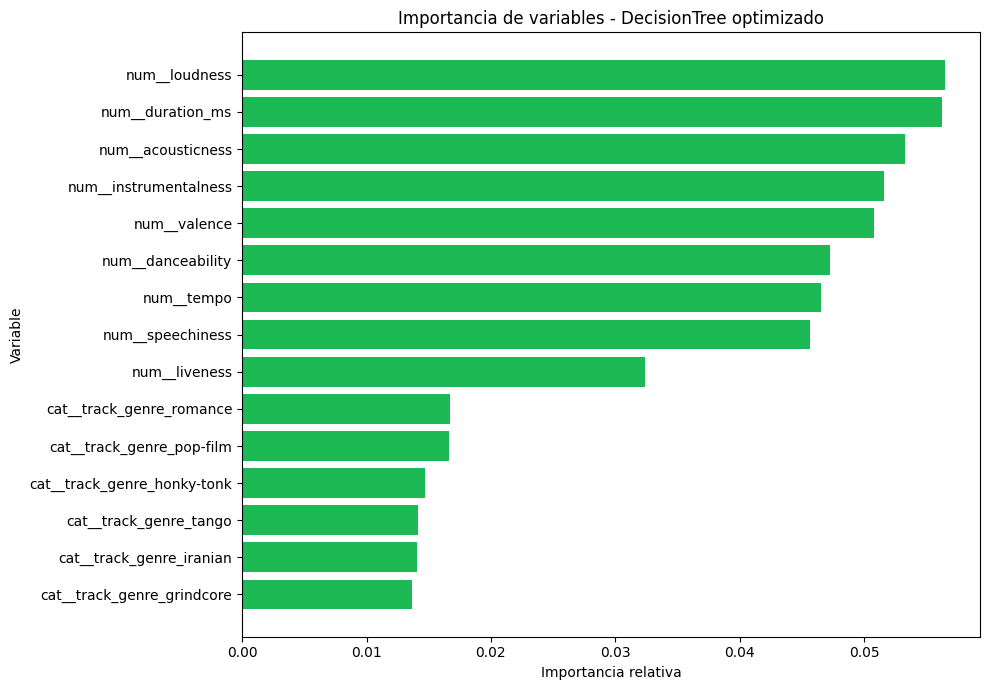

In [ ]:
# PASO 10: Importancia de variables del árbol optimizado

# Recuperar el preprocesador entrenado
preprocesador_entrenado = (
    modelo_optimizado.named_steps['preprocessor']
)

# Recuperar el árbol entrenado
arbol_optimizado = (
    modelo_optimizado.named_steps['classifier']
)

# Obtener nombres de características transformadas
nombres_variables = (
    preprocesador_entrenado.get_feature_names_out()
)

# Obtener importancia de cada característica
importancias = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': arbol_optimizado.feature_importances_
})

# Ordenar de mayor a menor importancia
importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

print("=== TOP 15 VARIABLES MÁS IMPORTANTES ===")
display(importancias.head(15))

# Visualización
top_importancias = importancias.head(15).sort_values(
    by='Importancia',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importancias['Variable'],
    top_importancias['Importancia'],
    color='#1DB954'
)

plt.title('Importancia de variables - DecisionTree optimizado')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

Se revisó qué características utilizó el árbol optimizado para realizar divisiones útiles.

Estos resultados ayudan a describir en qué características se apoya el modelo. Sin embargo, requieren tres cuidados:
- No indican causas del éxito: una importancia alta de volumen no demuestra que aumentar el volumen vuelva popular una canción.
- No indican la dirección del efecto: no dicen por sí solos si valores mayores o menores favorecen la categoría alta.
- Describen el árbol completo: reflejan la separación entre las tres categorías, no exclusivamente la identificación de canciones altas.

Además, track_genre aparece repartida en muchas columnas por el OneHotEncoder. Comparar una sola columna de género con una variable numérica no representa la importancia total del género.

##Interpretaciones

In [ ]:
# PASO 11: Diagnóstico final de los modelos

diferencia_f1 = f1_opt - f1_base

brecha_base = f1_train_base - f1_base
brecha_opt = f1_train_opt - f1_opt

print("=== DIAGNÓSTICO FINAL ===")

print(f"F1 Macro Base: {f1_base:.4f}")
print(f"F1 Macro Optimizado: {f1_opt:.4f}")

print(f"\nCambio en F1 Macro: {diferencia_f1:+.4f}")

print(f"Brecha Base: {brecha_base:.4f}")
print(f"Brecha Optimizado: {brecha_opt:.4f}")

if diferencia_f1 > 0:
    print("\nEl modelo optimizado obtuvo mayor F1 Macro en test.")
    modelo_ganador = modelo_optimizado
    nombre_ganador = "DecisionTree Optimizado"

elif diferencia_f1 < 0:
    print("\nEl modelo base obtuvo mayor F1 Macro en test.")
    modelo_ganador = modelo_base
    nombre_ganador = "DecisionTree Base"

else:
    print("\nAmbos modelos obtuvieron el mismo F1 Macro en test.")
    modelo_ganador = modelo_base
    nombre_ganador = "Empate - Base por simplicidad"

if brecha_opt < brecha_base:
    print("La optimización redujo la brecha Train-Test.")
elif brecha_opt > brecha_base:
    print("La optimización aumentó la brecha Train-Test.")
else:
    print("La brecha Train-Test se mantuvo.")

print(f"\nModelo seleccionado según F1 Macro: {nombre_ganador}")

# Evaluación especial de la clase comercialmente importante
print("\n=== RECALL DE POPULARIDAD ALTA ===")

recall_alta_base = recall_score(
    (y_test == 2).astype(int),
    (y_pred_base == 2).astype(int),
    zero_division=0
)

recall_alta_opt = recall_score(
    (y_test == 2).astype(int),
    (y_pred_opt == 2).astype(int),
    zero_division=0
)

print(f"Recall Alta - Base: {recall_alta_base:.4f}")
print(f"Recall Alta - Optimizado: {recall_alta_opt:.4f}")

=== DIAGNÓSTICO FINAL ===
F1 Macro Base: 0.6104
F1 Macro Optimizado: 0.6261

Cambio en F1 Macro: +0.0156
Brecha Base: 0.3825
Brecha Optimizado: 0.1575

El modelo optimizado obtuvo mayor F1 Macro en test.
La optimización redujo la brecha Train-Test.

Modelo seleccionado según F1 Macro: DecisionTree Optimizado

=== RECALL DE POPULARIDAD ALTA ===
Recall Alta - Base: 0.5052
Recall Alta - Optimizado: 0.4913


La conclusión para el objetivo comercial es que la optimización mejora el equilibrio general y reduce el sobreajuste, pero todavía identifica menos de la mitad de las canciones realmente altas.

#RandomForestClassifier

Se implementó Random Forest para evaluar si combinar muchos árboles consigue mejores resultados que utilizar uno solo. Cada árbol aprende con cierta aleatoriedad en las canciones y características utilizadas, y el conjunto combina sus predicciones.

Esto permite aprender distintas relaciones entre características musicales y reduce la dependencia de las decisiones de un único árbol. No garantiza eliminar el sobreajuste, por lo que también se compararon los resultados de entrenamiento y prueba.

Se mantuvieron las mismas categorías, predictores, datos de prueba y preparación con outliers para realizar una comparación consistente con Decision Tree.

##Paso 1: Comprobacion de datos

In [ ]:
# ============================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y VALIDACIÓN
# ============================================================
# Se utilizan los mismos conjuntos y el mismo preprocesador
# que en DecisionTreeClassifier para asegurar una comparación
# metodológicamente justa.

# Nombres de las clases
class_names = [
    'Baja',
    'Media',
    'Alta'
]

# Comprobar que el objetivo sigue siendo multiclase
print("Clases en entrenamiento:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nClases en prueba:")
print(pd.Series(y_test).value_counts().sort_index())

assert set(np.unique(y_train)) == {0, 1, 2}, \
    "y_train debe contener las clases 0, 1 y 2."

assert set(np.unique(y_test)) == {0, 1, 2}, \
    "y_test debe contener las clases 0, 1 y 2."

print("\nDimensiones:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

Clases en entrenamiento:
popularidad_clase
0    26708
1    28117
2    16967
Name: count, dtype: int64

Clases en prueba:
popularidad_clase
0    6677
1    7030
2    4242
Name: count, dtype: int64

Dimensiones:
X_train: (71792, 14)
X_test : (17949, 14)


Se verificó que entrenamiento y prueba conservaran las tres categorías: baja, media y alta. Esto es importante porque se reutilizan las variables del apartado anterior y debemos asegurarnos de que no correspondan al experimento binario.

La categoría alta sigue siendo la menos numerosa. Mantener estos mismos conjuntos permite atribuir las diferencias de rendimiento al modelo y su configuración, sin cambiar simultáneamente las canciones evaluadas.

##Paso 2. Construcción y entrenamiento del Random Forest base

In [ ]:
# ============================================================
# PASO 2: RANDOM FOREST BASE
# ============================================================
# Se utiliza RandomForestClassifier con sus hiperparámetros
# predictivos predeterminados, sin optimización previa.
#
# El preprocesador conserva los outliers y transforma las
# variables categóricas tal como en DecisionTreeClassifier.
#
# Se integra dentro del Pipeline para que las transformaciones
# se ajusten exclusivamente con los datos de entrenamiento.

rf_base = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenamiento
rf_base.fit(X_train, y_train)

# Predicciones
y_pred_rf_base = rf_base.predict(X_test)

# Predicciones sobre entrenamiento para analizar sobreajuste
y_pred_rf_base_train = rf_base.predict(X_train)

print("Random Forest base entrenado correctamente.")

Random Forest base entrenado correctamente.


Se entrenó un Random Forest con sus parámetros predictivos predeterminados. random_state=42 permite reproducir el experimento y n_jobs=-1 utiliza los procesadores disponibles para acelerar el trabajo.

**Se conservó el preprocesamiento anterior:**
- Variables numéricas sin escalamiento ni recorte de outliers.
- Categorías nominales transformadas mediante OneHotEncoder.
- Variables binarias utilizadas directamente.

El pipeline aprende las transformaciones con entrenamiento y después las aplica a prueba. Este modelo constituye la referencia para comprobar qué aporta la optimización.

##Paso 3. Evaluación del Random Forest base

In [ ]:
# ============================================================
# PASO 3: EVALUACIÓN DEL RANDOM FOREST BASE
# ============================================================
# Se utilizan las mismas métricas de clasificación del
# DecisionTreeClassifier para mantener la comparabilidad.
#
# Se incorpora MAE ordinal y Quadratic Weighted Kappa para
# considerar el orden natural de las clases de popularidad.

def evaluar_clasificador(nombre, y_real, y_pred):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision Macro': precision_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'Recall Macro': recall_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'F1 Macro': f1_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'MAE Ordinal': mean_absolute_error(
            y_real, y_pred
        ),
        'Kappa Cuadrático': cohen_kappa_score(
            y_real, y_pred,
            labels=[0, 1, 2],
            weights='quadratic'
        )
    }


# Métricas sobre test
metricas_rf_base = evaluar_clasificador(
    'Random Forest Base',
    y_test,
    y_pred_rf_base
)

display(
    pd.DataFrame([metricas_rf_base]).round(4)
)

# Reporte detallado por clase
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf_base,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Comparación del rendimiento de entrenamiento y prueba
f1_train_rf_base = f1_score(
    y_train,
    y_pred_rf_base_train,
    average='macro',
    zero_division=0
)

f1_test_rf_base = f1_score(
    y_test,
    y_pred_rf_base,
    average='macro',
    zero_division=0
)

print(f"F1 Macro Train: {f1_train_rf_base:.4f}")
print(f"F1 Macro Test : {f1_test_rf_base:.4f}")
print(f"Brecha Train-Test: "
      f"{f1_train_rf_base - f1_test_rf_base:.4f}")

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
0,Random Forest Base,0.7111,0.7072,0.6901,0.6955,0.3383,0.6129



Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.76      0.79      0.78      6677
       Media       0.68      0.74      0.71      7030
        Alta       0.68      0.54      0.60      4242

    accuracy                           0.71     17949
   macro avg       0.71      0.69      0.70     17949
weighted avg       0.71      0.71      0.71     17949

F1 Macro Train: 0.9930
F1 Macro Test : 0.6955
Brecha Train-Test: 0.2975


**Accuracy	71,11 %** Clasificó correctamente unas 71 de cada 100 canciones.

P**recision macro	0,7072** Promedio de la precision de las tres categorías.

**Recall macro	0,6901**	Promedio de la capacidad de detectar cada categoría.

**F1 macro	0,6955**	Equilibrio entre precision y recall, dando el mismo peso a cada clase.


*(No Pescar estas dos que las agregó gepeto para hacer una interpretacion "mas profunda y en detalle" pero de todas formas estan interesantes) *

**MAE ordinal	0,3383**	Distancia media entre categoría real y predicha. Menor es mejor.

**Kappa cuadrático	0,6129**	Acuerdo entre predicciones y clases reales, considerando el azar y penalizando más los errores alejados. Mayor es mejor.

-------------------------------------
**Para nuestro objetivo, lo más relevante es el resultado específico de alta:**
- Precision alta: 68,29 %.
- Recall alta: 54,22 %.
- F1 alta: 0,6045.

El modelo base selecciona canciones altas con una precision relativamente mayor, pero deja escapar casi la mitad de las que realmente pertenecen a ese grupo.
Además, su F1 macro pasa de 0,9930 en entrenamiento a 0,6955 en prueba. Esta diferencia indica que todavía existe sobreajuste.

##Paso 4. Matriz de confusión del modelo base

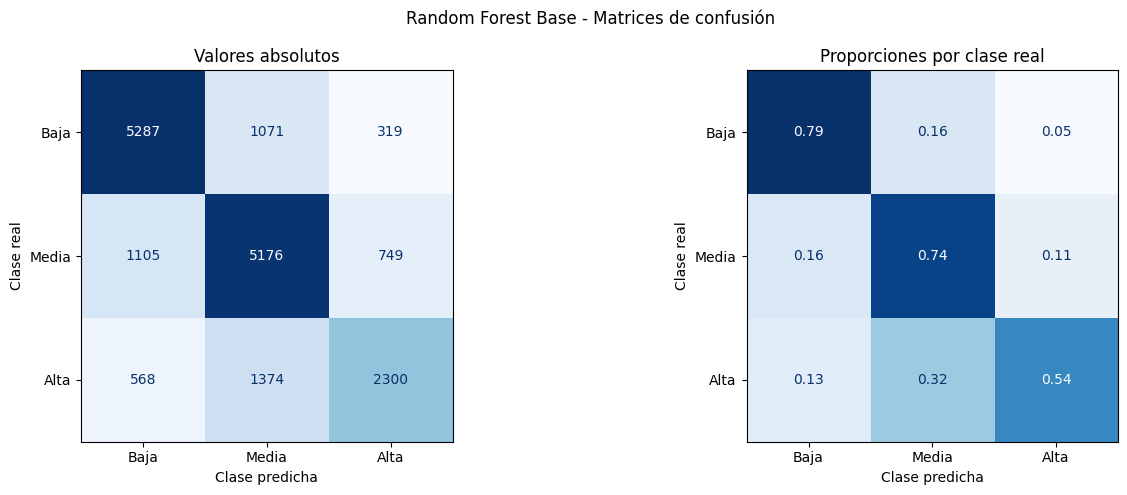

In [ ]:
# ============================================================
# PASO 4: MATRIZ DE CONFUSIÓN - RANDOM FOREST BASE
# ============================================================
# Permite identificar qué clases se confunden y si los
# errores ocurren entre categorías vecinas o extremas.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, normalize, titulo in [
    (axes[0], None, 'Valores absolutos'),
    (axes[1], 'true', 'Proporciones por clase real')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_rf_base,
        labels=[0, 1, 2],
        display_labels=class_names,
        normalize=normalize,
        cmap='Blues',
        values_format='d' if normalize is None else '.2f',
        ax=ax,
        colorbar=False
    )
    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.suptitle('Random Forest Base - Matrices de confusión')
plt.tight_layout()
plt.show()

La matriz se lee con categorías reales en las filas y predicciones en las columnas:

**La diagonal contiene los aciertos.**

Para estudiar las canciones altas debemos observar dos partes:

**Última fila: qué pasó con las canciones realmente altas**.

De las 4.242 canciones altas:
- 2.300 fueron identificadas correctamente.
- 1.374 fueron confundidas con medias.
- 568 fueron confundidas con bajas.

Por tanto, detectó el 54,22 % y dejó pasar el 45,78 %.

**Última columna: qué tan confiables son sus selecciones como altas.**

El modelo clasificó 3.368 canciones como altas:
- 2.300 realmente eran altas.
- 749 eran medias.
- 319 eran bajas.

Esto produce una precision de 68,29 %: aproximadamente 68 de cada 100 canciones seleccionadas como altas pertenecían realmente a ese grupo.
La matriz de proporciones del Colab está normalizada por fila. Su valor 0,54 en alta–alta representa el recall de alta. No representa la precision, porque esta utiliza el total de la columna.

##Paso 5. Búsqueda de hiperparámetro

In [ ]:
# ============================================================
# PASO 5: OPTIMIZACIÓN CON RANDOMIZEDSEARCHCV
# ============================================================
# Se busca mejorar la generalización del Random Forest.
#
# La validación cruzada es estratificada para mantener la
# proporción de las tres categorías de popularidad.
#
# Se optimiza F1 Macro para dar igual importancia a todas
# las clases, independientemente de su frecuencia.
#
# El preprocesamiento permanece dentro del Pipeline para
# evitar fuga de información durante la validación cruzada.

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

# Espacio de búsqueda de hiperparámetros
param_distributions = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 0.5],
    'classifier__class_weight': [None, 'balanced']
}

# Validación cruzada estratificada
cv_rf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Búsqueda aleatoria
random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='f1_macro',
    cv=cv_rf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

# Ajustar utilizando únicamente el conjunto de entrenamiento
random_search_rf.fit(X_train, y_train)

# Recuperar el mejor pipeline completo
rf_optimizado = random_search_rf.best_estimator_

print("\nMejores hiperparámetros:")
for parametro, valor in random_search_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor F1 Macro promedio en CV: "
    f"{random_search_rf.best_score_:.4f}"
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Mejores hiperparámetros:
classifier__n_estimators: 350
classifier__min_samples_split: 5
classifier__min_samples_leaf: 2
classifier__max_features: sqrt
classifier__max_depth: None
classifier__class_weight: balanced

Mejor F1 Macro promedio en CV: 0.6929


Se utilizó RandomizedSearchCV para evaluar diez configuraciones mediante tres divisiones de validación cruzada. Esta búsqueda permite explorar distintas opciones sin entrenar todas las combinaciones posibles

**n_estimators**	Cantidad de árboles del conjunto.

**max_depth**	Profundidad permitida de los árboles.

**min_samples_split**	Cantidad mínima de canciones para dividir un nodo.

**min_samples_leaf**	Cantidad mínima de canciones en un grupo final.

**max_features**	Características consideradas al buscar cada división.

**class_weight**	Peso asignado a cada categoría durante el aprendizaje.

La mejor configuración encontrada utilizó 350 árboles, min_samples_split=5, min_samples_leaf=2, max_features='sqrt', profundidad sin límite y class_weight='balanced'.

Aquí sí se aplicó una medida durante el entrenamiento para considerar el desbalance. balanced da mayor peso a las clases menos numerosas, como alta. No crea canciones ni iguala sus cantidades: cambia cuánto influye cada clase al aprender.

También se mantuvieron la validación estratificada y F1 macro como criterio de selección. La búsqueda se realizó únicamente sobre entrenamiento.
La mejora observada corresponde a la combinación completa de ajustes; no podemos atribuirla exclusivamente a class_weight.

##Paso 6. Visualizar los resultados de la búsqueda

In [ ]:
# ============================================================
# PASO 6: RESULTADOS DE LA BÚSQUEDA
# ============================================================
# Se comparan las configuraciones evaluadas mediante
# sus resultados de F1 Macro en validación cruzada.

resultados_busqueda_rf = pd.DataFrame(
    random_search_rf.cv_results_
)

columnas_resultados = [
    'rank_test_score',
    'mean_train_score',
    'mean_test_score',
    'std_test_score',
    'params'
]

display(
    resultados_busqueda_rf[columnas_resultados]
    .sort_values('rank_test_score')
    .head(10)
    .round(4)
)

,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
4,1,0.9223,0.6929,0.0043,"{'classifier__n_estimators': 350, 'classifier_..."
0,2,0.9301,0.6875,0.0044,"{'classifier__n_estimators': 250, 'classifier_..."
6,3,0.9824,0.6864,0.0052,"{'classifier__n_estimators': 150, 'classifier_..."
8,4,0.9601,0.6825,0.0021,"{'classifier__n_estimators': 150, 'classifier_..."
2,5,0.8095,0.6719,0.0039,"{'classifier__n_estimators': 150, 'classifier_..."
5,6,0.6487,0.5868,0.0032,"{'classifier__n_estimators': 350, 'classifier_..."
9,7,0.6345,0.5507,0.0028,"{'classifier__n_estimators': 250, 'classifier_..."
7,8,0.6086,0.5498,0.0017,"{'classifier__n_estimators': 250, 'classifier_..."
1,9,0.5558,0.5316,0.0043,"{'classifier__n_estimators': 150, 'classifier_..."
3,10,0.4520,0.4421,0.0054,"{'classifier__n_estimators': 150, 'classifier_..."


La tabla permite comparar las configuraciones según su F1 macro promedio de validación y comprobar cuánto varían sus resultados entre divisiones.
La mejor configuración obtuvo:
- F1 macro promedio de entrenamiento: 0,9223.
- F1 macro promedio de validación: 0,6929.
- Variación entre divisiones, medida mediante desviación estándar: 0,0043.

El resultado cambia poco entre esas divisiones, pero continúa existiendo una diferencia importante entre entrenamiento y validación.
En esta tabla, mean_test_score corresponde a las divisiones de validación cruzada, no al conjunto final de prueba.

##Paso 7. Predicciones y métricas finales

In [ ]:
# ============================================================
# PASO 7: EVALUACIÓN DEL RANDOM FOREST OPTIMIZADO
# ============================================================
# Se evalúa el mejor modelo sobre el conjunto de prueba,
# que no participó en la optimización.

# Predicciones
y_pred_rf_opt = rf_optimizado.predict(X_test)
y_pred_rf_opt_train = rf_optimizado.predict(X_train)

# Métricas sobre test
metricas_rf_opt = evaluar_clasificador(
    'Random Forest Optimizado',
    y_test,
    y_pred_rf_opt
)

display(
    pd.DataFrame([metricas_rf_opt]).round(4)
)

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf_opt,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Evaluación del posible sobreajuste
f1_train_rf_opt = f1_score(
    y_train,
    y_pred_rf_opt_train,
    average='macro',
    zero_division=0
)

f1_test_rf_opt = f1_score(
    y_test,
    y_pred_rf_opt,
    average='macro',
    zero_division=0
)

print(f"F1 Macro Train: {f1_train_rf_opt:.4f}")
print(f"F1 Macro Test : {f1_test_rf_opt:.4f}")
print(
    f"Brecha Train-Test: "
    f"{f1_train_rf_opt - f1_test_rf_opt:.4f}"
)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
0,Random Forest Optimizado,0.7116,0.7017,0.7039,0.7027,0.3443,0.6176



Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.76      0.78      0.77      6677
       Media       0.71      0.69      0.70      7030
        Alta       0.63      0.64      0.64      4242

    accuracy                           0.71     17949
   macro avg       0.70      0.70      0.70     17949
weighted avg       0.71      0.71      0.71     17949

F1 Macro Train: 0.9197
F1 Macro Test : 0.7027
Brecha Train-Test: 0.2170


La accuracy prácticamente no cambia. Sin embargo, la categoría alta sí cambia de manera relevante, algo que veremos en su matriz.

El F1 macro de entrenamiento baja a 0,9197, frente a 0,7027 en prueba. La brecha es aproximadamente 0,2170, menor que la del modelo base, aunque sigue mostrando sobreajuste.

##Paso 8. Comparación entre Random Forest base y optimizado

,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Random Forest Base,0.7111,0.7072,0.6901,0.6955,0.3383,0.6129
Random Forest Optimizado,0.7116,0.7017,0.7039,0.7027,0.3443,0.6176



Diferencias: optimizado - base


,0
Accuracy,0.0005
Precision Macro,-0.0055
Recall Macro,0.0138
F1 Macro,0.0072
MAE Ordinal,0.0060
Kappa Cuadrático,0.0047


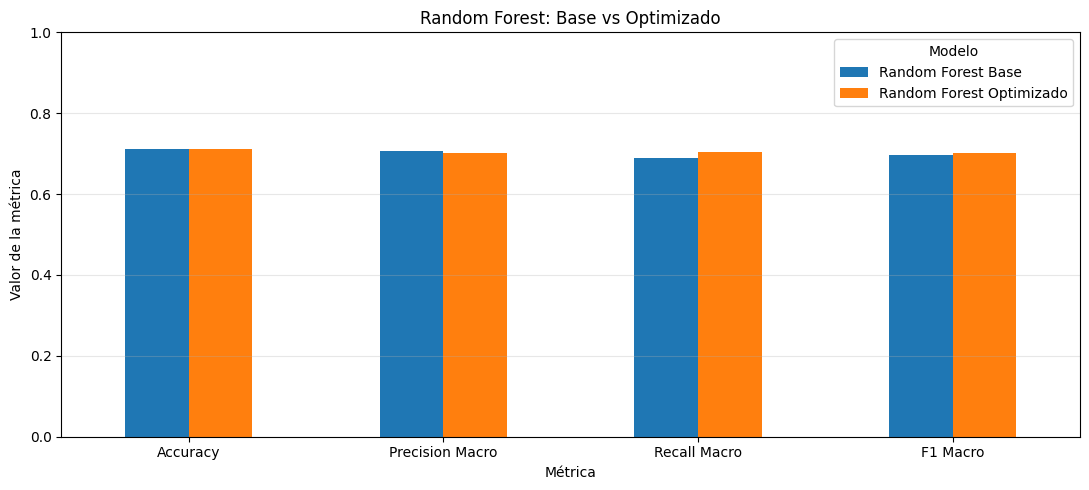

In [ ]:
# ============================================================
# PASO 8: COMPARACIÓN BASE VS OPTIMIZADO
# ============================================================
# Se comparan las métricas obtenidas sobre el mismo conjunto
# de prueba, manteniendo las mismas variables y preprocesamiento.

comparacion_rf = pd.DataFrame([
    metricas_rf_base,
    metricas_rf_opt
]).set_index('Modelo')

display(comparacion_rf.round(4))

# Diferencias del optimizado respecto al base
diferencias_rf = (
    comparacion_rf.loc['Random Forest Optimizado']
    - comparacion_rf.loc['Random Forest Base']
)

print("\nDiferencias: optimizado - base")
display(diferencias_rf.round(4))

# Gráfico de métricas principales
metricas_grafico = [
    'Accuracy',
    'Precision Macro',
    'Recall Macro',
    'F1 Macro'
]

comparacion_rf[metricas_grafico].T.plot(
    kind='bar',
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Random Forest: Base vs Optimizado')
plt.ylabel('Valor de la métrica')
plt.xlabel('Métrica')
plt.legend(title='Modelo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

La optimización no mejora todas las métricas:
- Aumenta recall macro y F1 macro.
- Reduce precision macro.
- Mantiene casi igual la accuracy.
- Empeora ligeramente el MAE ordinal.

Esto muestra que no basta con decir “el optimizado es mejor” sin explicar para qué objetivo.

En este caso, el beneficio más relevante es detectar más canciones altas. El coste es seleccionar también más canciones que realmente son bajas o medias. La pequeña mejora de accuracy oculta ese cambio comercialmente importante.

##Paso 9. Matriz de confusión del Random Forest optimizado

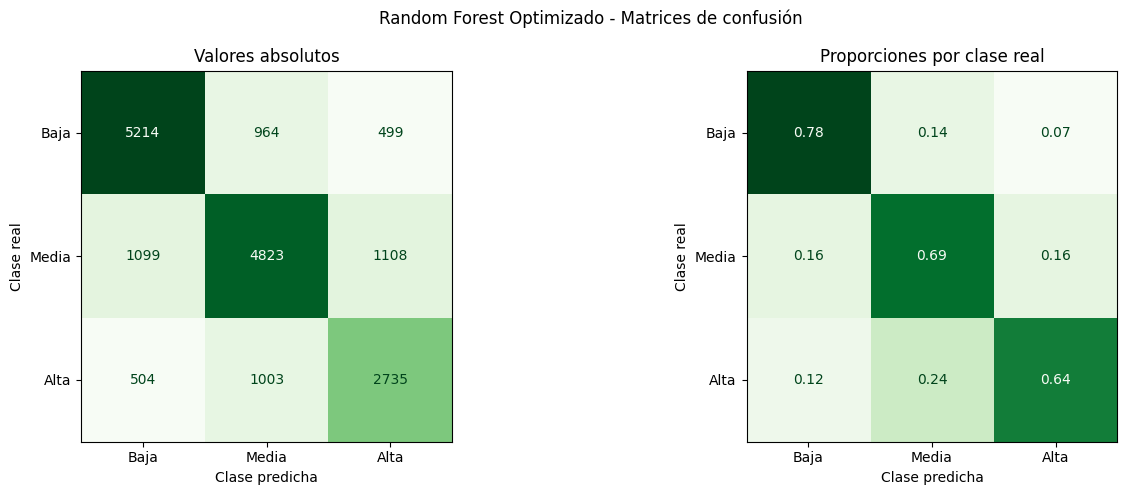

In [ ]:
# ============================================================
# PASO 9: MATRIZ DE CONFUSIÓN - RANDOM FOREST OPTIMIZADO
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, normalize, titulo in [
    (axes[0], None, 'Valores absolutos'),
    (axes[1], 'true', 'Proporciones por clase real')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_rf_opt,
        labels=[0, 1, 2],
        display_labels=class_names,
        normalize=normalize,
        cmap='Greens',
        values_format='d' if normalize is None else '.2f',
        ax=ax,
        colorbar=False
    )
    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.suptitle('Random Forest Optimizado - Matrices de confusión')
plt.tight_layout()
plt.show()

**Altas correctamente detectadas	2.735**	Canciones del grupo de interés identificadas correctamente.

**Altas confundidas con medias	1.003**	Canciones altas que quedarían fuera si seleccionamos únicamente las predichas como altas.

**Altas confundidas con bajas	50**4	Canciones altas subestimadas en dos categorías.

**Medias clasificadas como altas	1.108**	Selecciones incorrectas procedentes del grupo medio.

**Bajas clasificadas como altas	499**	Selecciones incorrectas procedentes del grupo bajo.

------------------------------------------------------------------------
Recall alta: ¿cuántas de las realmente altas encontramos?
- Detecta aproximadamente 64 de cada 100 canciones realmente altas. Deja escapar 1.507, equivalentes al 35,53 %.

Precision alta: ¿cuántas de las seleccionadas como altas lo son realmente?
- De las 4.342 canciones seleccionadas como altas, 2.735 lo eran. Aproximadamente 63 de cada 100 selecciones son correctas; las otras 37 pertenecen a baja o media.

F1 alta: equilibrio entre ambas medidas
- Su F1 de alta es 0,6372, frente a 0,6045 del modelo base. Mejora el equilibrio entre detección y precision.

--------------------------------------------------------------------------
La optimización recupera 435 canciones altas adicionales, pero genera 539 selecciones incorrectas adicionales como altas.
Para interpretar el beneficio:
- Si buscamos encontrar más canciones realmente altas para revisarlas, priorizamos recall y el optimizado resulta más adecuado.
- Si vamos a invertir directamente en una selección con presupuesto limitado, importa especialmente la precision; el base realiza menos selecciones incorrectas proporcionalmente.

La fila alta de la matriz normalizada del optimizado se interpreta así: aproximadamente 11,88 % de las altas fueron clasificadas como bajas, 23,64 % como medias y 64,47 % correctamente como altas.

##Paso 10. Tabla comparativa de modelos

In [ ]:
# ============================================================
# PASO 10: COMPARACIÓN DECISION TREE VS RANDOM FOREST
# ============================================================
# IMPORTANTE:
# Sustituir los nombres y_pred_dt_base y y_pred_dt_opt
# si se utilizaron otros en la sección anterior.

metricas_dt_base = evaluar_clasificador(
    'Decision Tree Base',
    y_test,
    y_pred_base
)

metricas_dt_opt = evaluar_clasificador(
    'Decision Tree Optimizado',
    y_test,
    y_pred_opt
)

# Tabla comparativa general
comparacion_modelos = pd.DataFrame([
    metricas_dt_base,
    metricas_dt_opt,
    metricas_rf_base,
    metricas_rf_opt
]).set_index('Modelo')

display(
    comparacion_modelos.round(4)
)

# Ordenar por F1 Macro
ranking_modelos = comparacion_modelos.sort_values(
    by='F1 Macro',
    ascending=False
)

print("\nRanking según F1 Macro:")
display(ranking_modelos.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Decision Tree Base,0.6244,0.6109,0.6102,0.6104,0.4484,0.4953
Decision Tree Optimizado,0.6428,0.6294,0.6244,0.6261,0.4257,0.5143
Random Forest Base,0.7111,0.7072,0.6901,0.6955,0.3383,0.6129
Random Forest Optimizado,0.7116,0.7017,0.7039,0.7027,0.3443,0.6176



Ranking según F1 Macro:


,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Random Forest Optimizado,0.7116,0.7017,0.7039,0.7027,0.3443,0.6176
Random Forest Base,0.7111,0.7072,0.6901,0.6955,0.3383,0.6129
Decision Tree Optimizado,0.6428,0.6294,0.6244,0.6261,0.4257,0.5143
Decision Tree Base,0.6244,0.6109,0.6102,0.6104,0.4484,0.4953


La tabla general muestra que los dos Random Forest superan a los árboles individuales en accuracy y F1 macro. Pero para el negocio debemos añadir la comparación específica de alta:


#**Resumen y decision**

(By: ChatGPT)

El objetivo del negocio es identificar canciones que realmente pertenecen a la categoría de popularidad alta, utilizando sus características musicales y género. Esto permitiría apoyar la búsqueda de canciones de interés para análisis y posibles acciones de promoción. La predicción identifica asociaciones con la popularidad observada; no garantiza éxito futuro ni demuestra qué características lo causan.

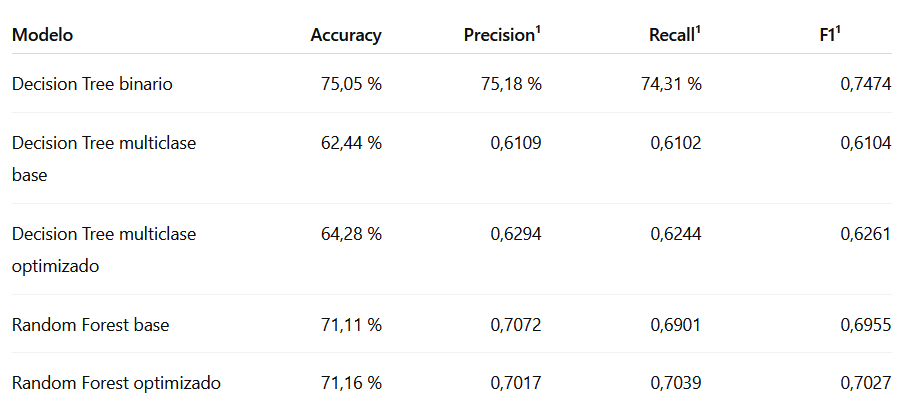

En el modelo binario, precision, recall y F1 corresponden a su categoría alta. En los modelos multiclase son promedios macro, que dan la misma importancia a las tres categorías.

La accuracy indica la proporción total de canciones correctamente clasificadas. La precision muestra qué tan confiables son las selecciones de cada categoría; el recall, cuántas canciones de esa categoría consigue detectar; y F1 resume el equilibrio entre ambas. F1 no representa un porcentaje de aciertos.

La optimización mejoró el desempeño general de Decision Tree y redujo su sobreajuste. Random Forest obtuvo mejores resultados generales que los árboles individuales. Su optimización apenas cambió la accuracy, pero produjo una mejora importante en la detección de canciones altas.

**Resultados relevantes para el negocio**

- Como interesa encontrar las canciones realmente altas, debemos observar principalmente el recall de alta popularidad, acompañado de precision y F1 de esa misma clase

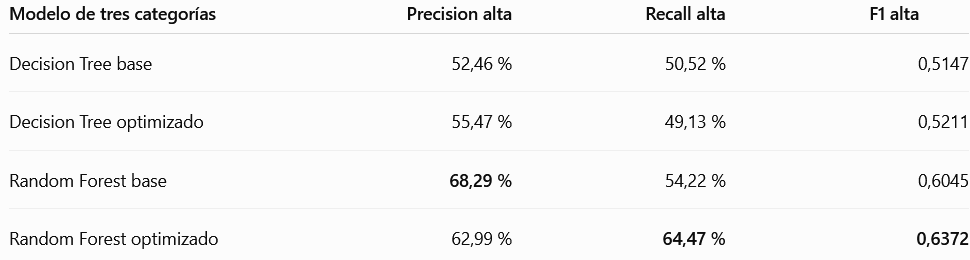

El Random Forest optimizado detectó 2.735 de las 4.242 canciones realmente altas, dejando pasar 1.507. Su recall de 64,47 % significa que recupera aproximadamente 64 de cada 100 canciones del grupo que nos interesa.

Su precision de 62,99 % significa que aproximadamente 63 de cada 100 canciones clasificadas como altas realmente lo son. Por tanto, detectar más canciones altas también implica aceptar algunas selecciones incorrectas.

Si el objetivo fuera invertir directamente un presupuesto limitado en pocas canciones, la precision cobraría mayor importancia: en ese caso, el Random Forest base ofrece selecciones proporcionalmente más confiables.

**Métricas complementarias y sobreajuste**

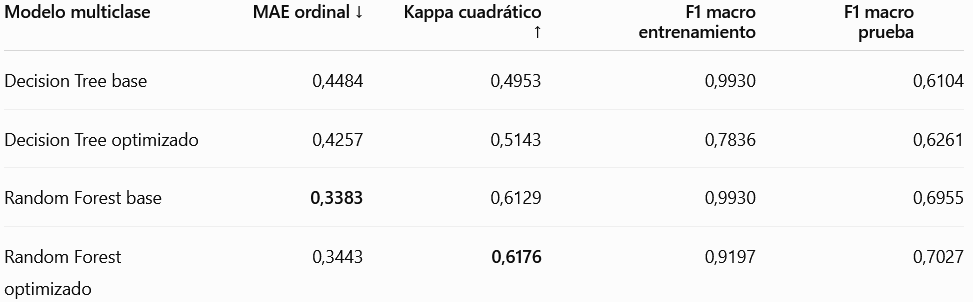

El MAE ordinal mide cuántas categorías se aleja, en promedio, la predicción de la respuesta real. El kappa cuadrático mide el acuerdo considerando el azar y penaliza más confundir baja con alta que confundir categorías vecinas.

Las diferencias entre entrenamiento y prueba muestran sobreajuste en todos los modelos. La optimización lo reduce, pero no lo elimina. El árbol binario también presenta una diferencia importante: su accuracy baja de 99,57 % en entrenamiento a 75,05 % en prueba.

#**¿Con qué modelo me quedaría y por qué?**

Me quedaría con Random Forest optimizado para el objetivo actual. Obtiene el mayor recall y F1 de alta popularidad, por lo que ofrece el mejor resultado entre los modelos evaluados para recuperar canciones realmente altas.

Frente al Random Forest base, detecta 435 canciones altas adicionales, aunque genera 539 selecciones incorrectas adicionales como altas. Lo utilizaría para apoyar una selección inicial que posteriormente pueda revisarse, teniendo presente que todavía pierde alrededor del 36 % de las canciones altas.

(pregunta que posiblemente haga la profe jazna y es importante considerar)

**¿Se puede comparar el modelo binario con los de tres categorías?**
Se pueden contrastar como experimentos distintos, pero no utilizar sus métricas directamente para afirmar cuál es mejor.

El binario resuelve una tarea más simple y define alta como 34–100. Los modelos de tres categorías definen alta como 50–100. Por ejemplo, una canción con 40 puntos es alta en el experimento binario y media en el multiclase.

Además, las métricas del binario se calculan para su clase alta, mientras que las generales del multiclase son promedios macro. Por eso, el 75,05 % de accuracy del binario no demuestra que sea superior para el negocio: distingue menos categorías y responde una pregunta diferente.

Para una comparación directa, ambos tendrían que evaluarse sobre las mismas canciones, con una definición común de “alta” y las mismas métricas.

**¿Que significa macro y como interpretarlo?**

**“Macro”** significa calcular una métrica para cada categoría y después sacar el promedio, dando la misma importancia a las tres.

se evalúa por separado baja, media y alta popularidad. Aunque haya menos canciones altas, su resultado pesa lo mismo en el promedio.

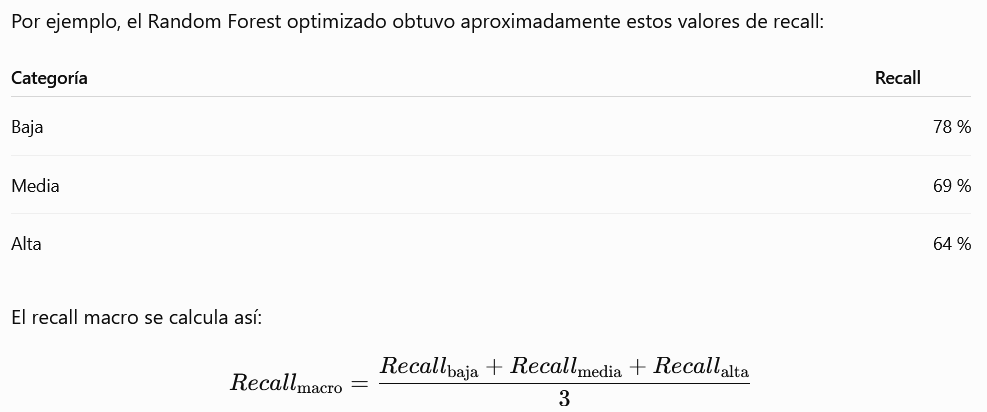

Con los valores completos, sin redondear, tu resultado es 0,7039, equivalente al 70,39 %.

--------------------------------------------------------------------------
¿Cómo lo interpreto?

- El modelo detecta, en promedio entre las tres categorías y dando igual importancia a cada una, el 70,39 % de las canciones de su respectiva categoría

Eso no significa que detecte el 70,39 % de las canciones altas. Para alta, el recall específico es 64,47 %.

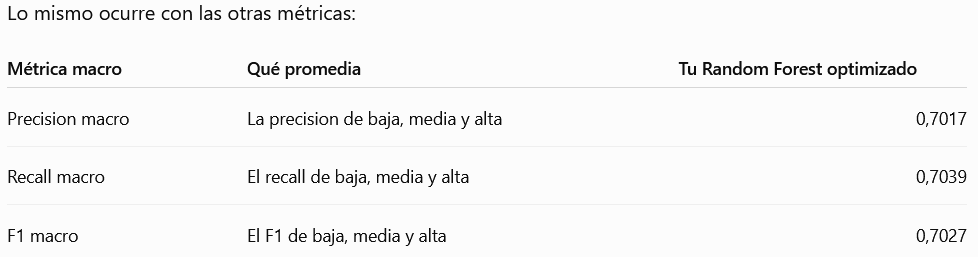

F1 macro de 0,7027 no significa que acertó el 70,27 % de las canciones. El porcentaje total de aciertos lo mide la accuracy, que en ese modelo es 71,16 %.

Usamos macro porque permite evaluar el equilibrio entre las tres categorías sin que las más numerosas dominen el promedio. Para tu objetivo de encontrar canciones realmente altas, debes mirar además el recall de alta: 64,47 %.

#Exportacion Dataset

In [ ]:
# PASO 2: IDENTIFICAR Y VALIDAR LOS MODELOS
# Se exportan los pipelines completos para conservar
# la codificación de variables y el clasificador entrenado.

modelos_exportar = {
    "decision_tree_multiclase_base": modelo_base,
    "decision_tree_multiclase_optimizado": modelo_optimizado,
    "random_forest_multiclase_base": rf_base,
    "random_forest_multiclase_optimizado": rf_optimizado
}

# Comprobar todos los modelos antes de comenzar la exportación
for nombre, pipeline in modelos_exportar.items():
    check_is_fitted(pipeline.named_steps["classifier"])
    print(f"Modelo entrenado: {nombre}")

# Carpeta de destino
carpeta_exportacion = Path("modelos_clasificacion_spotify")
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

Modelo entrenado: decision_tree_multiclase_base
Modelo entrenado: decision_tree_multiclase_optimizado
Modelo entrenado: random_forest_multiclase_base
Modelo entrenado: random_forest_multiclase_optimizado


In [ ]:
# PASO 3: EXPORTAR MODELOS E HIPERPARÁMETROS
# .joblib: pipeline entrenado y listo para realizar predicciones.
# .json: configuración del clasificador, fácil de consultar.

for nombre, pipeline in modelos_exportar.items():

    # 1. Guardar el pipeline completo
    ruta_modelo = carpeta_exportacion / f"{nombre}.joblib"

    joblib.dump(
        pipeline,
        ruta_modelo,
        compress=3
    )

    # 2. Obtener los hiperparámetros del clasificador
    hiperparametros = (
        pipeline.named_steps["classifier"]
        .get_params(deep=False)
    )

    # 3. Guardar los hiperparámetros
    ruta_parametros = (
        carpeta_exportacion / f"{nombre}_hiperparametros.json"
    )

    with ruta_parametros.open("w", encoding="utf-8") as archivo:
        json.dump(
            hiperparametros,
            archivo,
            indent=4,
            ensure_ascii=False
        )

    print(f"\nExportado: {ruta_modelo}")
    print(f"Configuración: {ruta_parametros}")

print("\nExportación completada.")


Exportado: modelos_clasificacion_spotify/decision_tree_multiclase_base.joblib
Configuración: modelos_clasificacion_spotify/decision_tree_multiclase_base_hiperparametros.json

Exportado: modelos_clasificacion_spotify/decision_tree_multiclase_optimizado.joblib
Configuración: modelos_clasificacion_spotify/decision_tree_multiclase_optimizado_hiperparametros.json

Exportado: modelos_clasificacion_spotify/random_forest_multiclase_base.joblib
Configuración: modelos_clasificacion_spotify/random_forest_multiclase_base_hiperparametros.json

Exportado: modelos_clasificacion_spotify/random_forest_multiclase_optimizado.joblib
Configuración: modelos_clasificacion_spotify/random_forest_multiclase_optimizado_hiperparametros.json

Exportación completada.


In [ ]:
# PASO 4: COMPRIMIR Y DESCARGAR LOS ARCHIVOS

ruta_zip = shutil.make_archive(
    base_name="modelos_clasificacion_spotify",
    format="zip",
    root_dir=str(carpeta_exportacion)
)

print(f"ZIP generado: {ruta_zip}")

from google.colab import files
files.download(ruta_zip)

ZIP generado: /content/modelos_clasificacion_spotify.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>